# Which curve shape fits grams → ml?

The simulator turns each ingredient's portion weight into a volume with a fitted curve,
currently a power law **ml = K·g^p** (`src/core/curves.cc`). This notebook asks whether
the measurements in `data/measurements/` support that shape, or whether another
one fits better.

**Approach**

1. Load the curve points exactly as the app does: single-ingredient bowl rows with no sauce cups,
   the camera's empty-bowl reading taken off each scan, and grams rescaled to `scale_g` when a row has it.
2. Fit a set of candidate shapes per ingredient by least squares on ml, the same objective the app uses.
   Two of them also let each measurement session differ.
3. Score each fit with **AICc**, **BIC**, and **leave-one-out (LOO) RMSE**.

**Reading the scores.** AIC = 2k − 2·log L rewards fit and charges 2 per parameter.
AICc adds a small-sample correction, which matters for the ingredients with fewer points.
BIC charges log(n) per parameter, so it leans further toward simple models.
Only *differences* matter. A rule of thumb for ΔAICc:
- **< 2:** about equally supported
- **4–7:** clearly less supported
- **> 10:** essentially no support

Akaike weights, exp(−ΔAICc/2) normalised to sum to 1, read as the relative support for each model within the set.

In [1]:
import glob
import math
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = "data/measurements"
EMPTY_BOWL_ML = -5.0   # Settings → Measurements → Empty-bowl reading (app default)
MIN_N = 8              # fewer points than this can't usefully separate 3-parameter models

# Validated categorical palette, fixed order (dataviz reference palette)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#a9a8a2"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.titlesize": 10,
    "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)

## 1. Load the measurements the way the app does

A bowl sheet is **wide**: one column per ingredient holding grams (blank when the bowl doesn't have it),
then `ml`, plus optional `cups`, `lid`, `scale_g` and `notes`. A curve needs **long** data, one row per
`(ingredient, g, ml)` point. Getting from one to the other is ordinary `pd.read_csv` plus a few rules the app
applies, from `load_bowl_csv` and `single_ingredient_points` (`src/core/bowl_data.cc`):

| Rule | Why |
|---|---|
| ml − `EMPTY_BOWL_ML` | the camera reads an empty bowl at about −5 ml |
| grams × `scale_g` / row total, when `scale_g` is set | trusted bench-scale total; the robot's puck drifts |
| keep rows with exactly **one** ingredient | mixed bowls fit the base squash, not curves |
| drop rows with sauce `cups` > 0 | the cups add volume that isn't the ingredient |
| clean header names (`clean_name`) | `"Mexican Rice [Retherm]"` and `"Mexican Rice"` are one curve |
| match names regardless of case; the first spelling seen names the curve | `CurveSet::refit` |

Backfill and drop-impossible are off, which are the app defaults.

Here is one raw file, just as `pd.read_csv` gives it:

In [2]:
example_file = "bowl_data_20261019_1.csv"
example = pd.read_csv(os.path.join(DATA_DIR, example_file), skip_blank_lines=False)
example.dropna(axis=1, how="all").head(8)    # hide the all-empty ingredient columns for display

,white rice,Guajillo Cumin Chicken cooked,ml,cups,scale_g,notes
0,NaN,146.9,171,0.0,NaN,NaN
1,83.4,NaN,157,NaN,NaN,NaN
2,56.0,NaN,96,NaN,NaN,NaN
3,84.7,NaN,151,NaN,NaN,NaN
4,105.8,NaN,198,NaN,NaN,NaN
5,86.1,NaN,158,NaN,NaN,NaN
6,94.9,NaN,167,NaN,NaN,NaN
7,108.9,NaN,207,NaN,NaN,NaN


In [3]:
def clean_name(raw):
    # Same steps as clean_name in src/core/menu_loader.cc
    s = re.sub(r"\[[^\]]*\]|\([^)]*\)", "", raw)                                        # [Retherm], (v2)
    s = re.sub(r"\b(retherm|rethermed|cooked|portion|portioned|v\d+(\.\d+)*)\b", "", s, flags=re.I)
    s = re.sub(r"[^\w\s'&+-]", " ", s)                                                  # stray punctuation
    s = re.sub(r"\s+", " ", s).strip()                                                  # "Guajillo  Cumin"
    return s or raw.strip()

META = {"ml", "oz", "cups", "lid", "notes", "scale_g", "total_g", "scale_total_g"}
SCALE_COLS = ["scale_g", "total_g", "scale_total_g"]

def curve_points(df, file):
    # One bowl sheet (as read by pd.read_csv) -> long curve points.
    num = lambda col: pd.to_numeric(col, errors="coerce")       # blanks / text -> NaN
    df = df.rename(columns=str.strip)
    cols = {c.lower(): c for c in df.columns}                   # headers match regardless of case
    ing_cols = [c for c in df.columns if c.lower() not in META]

    grams = df[ing_cols].apply(num).where(lambda x: x > 0)      # NaN = ingredient not in this bowl
    ml = num(df[cols["ml"]]) - EMPTY_BOWL_ML
    cups = num(df[cols["cups"]]).fillna(0) if "cups" in cols else 0

    scale_col = next((cols[c] for c in SCALE_COLS if c in cols), None)
    if scale_col:
        scale = num(df[scale_col])
        grams = grams.mul((scale / grams.sum(axis=1)).where(scale > 0, 1.0), axis=0)

    single = (grams.notna().sum(axis=1) == 1) & (ml > 0) & (cups <= 0)
    long = (grams[single]
            .stack().dropna()                                   # wide -> long: (row, column) -> grams
            .rename_axis(["row", "column"])
            .reset_index(name="g"))
    long["ml"] = ml.loc[long.row].to_numpy()
    long["ingredient"] = long.column.map(clean_name)
    long["file"] = file
    long["line"] = long.row + 2                                 # header is line 1
    return long[["ingredient", "g", "ml", "file", "line"]]

curve_points(example, example_file).head(8)

,ingredient,g,ml,file,line
0,Guajillo Cumin Chicken,146.9,176.0,bowl_data_20261019_1.csv,2
1,white rice,83.4,162.0,bowl_data_20261019_1.csv,3
2,white rice,56.0,101.0,bowl_data_20261019_1.csv,4
3,white rice,84.7,156.0,bowl_data_20261019_1.csv,5
4,white rice,105.8,203.0,bowl_data_20261019_1.csv,6
5,white rice,86.1,163.0,bowl_data_20261019_1.csv,7
6,white rice,94.9,172.0,bowl_data_20261019_1.csv,8
7,white rice,108.9,212.0,bowl_data_20261019_1.csv,9


The same function runs over every file in the folder. Files starting with `.` (LibreOffice lock files)
are skipped, as are curve-row files (`ingredient, g, ml`); the folder currently has none.
Each file counts as one **session**, a sitting where the food came from one batch on one setup.

In [4]:
frames = []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    file = os.path.basename(path)
    if file.startswith("."):
        continue
    df = pd.read_csv(path, skip_blank_lines=False)
    if {"ingredient", "name"} & {c.strip().lower() for c in df.columns}:
        print(f"skipping curve-row file {file}")
        continue
    frames.append(curve_points(df, file))
pts = pd.concat(frames, ignore_index=True)

# Names match regardless of case; the first spelling seen names the curve
key = pts.ingredient.str.lower()
pts["ingredient"] = key.map(pts.groupby(key).ingredient.first())
pts["session"] = pts.file.str.removeprefix("bowl_data_").str.removesuffix(".csv")
# Names starting with "test" are calibration references (is_reference_name), not foods
pts["reference"] = key.str.startswith("test")

summary = (pts.groupby("ingredient")
              .agg(n=("g", "size"), g_min=("g", "min"), g_max=("g", "max"),
                   ml_min=("ml", "min"), ml_max=("ml", "max"), reference=("reference", "first"),
                   sessions=("session", "nunique"))
              .sort_values("n", ascending=False))
summary["compared"] = summary.n >= MIN_N
summary

,n,g_min,g_max,ml_min,ml_max,reference,sessions,compared
ingredient,,,,,,,,
test beans,82,2.29,459.7,2.0,507.0,True,1,True
white rice,48,56.00,383.0,101.0,721.0,False,2,True
lemon couscous,47,44.80,204.5,49.0,295.0,False,2,True
Romaine Base,42,39.00,100.4,148.0,590.0,False,2,True
Guajillo Cumin Chicken,32,60.30,330.6,52.0,445.0,False,1,True
Chicken Al Pastor,6,57.00,181.0,37.0,181.0,False,1,False
Pineapple-Cucumber Salad,6,39.00,77.0,36.0,63.0,False,1,False
Pico de Gallo,6,29.00,53.0,13.0,37.0,False,1,False
Mexican Slaw,6,34.00,94.0,80.0,248.0,False,1,False


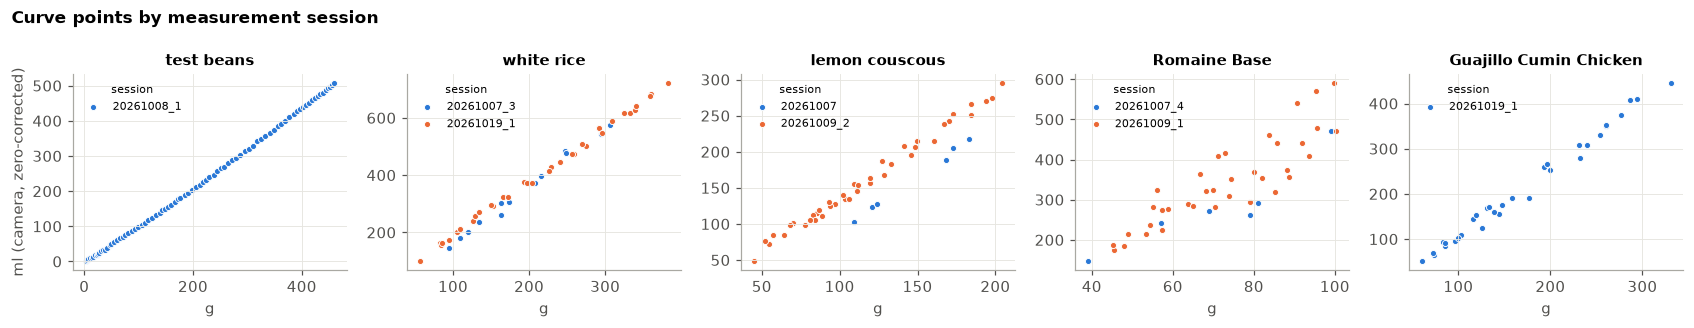

In [5]:
ingredients = summary.index[summary.compared].tolist()
fig, axes = plt.subplots(1, len(ingredients), figsize=(3.1 * len(ingredients), 3), squeeze=False)
for ax, name in zip(axes[0], ingredients):
    d = pts[pts.ingredient == name]
    for i, (sess, df) in enumerate(d.groupby("session")):
        ax.scatter(df.g, df.ml, s=16, color=SERIES[i % len(SERIES)], edgecolor="white", linewidth=0.6, label=sess)
    ax.set_title(name)
    ax.set_xlabel("g")
    ax.legend(fontsize=7, title="session", title_fontsize=7)
axes[0][0].set_ylabel("ml (camera, zero-corrected)")
fig.suptitle("Curve points by measurement session", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

## 2. Candidate models

| Model | Shape | k (mean) | What it would mean |
|---|---|---|---|
| `linear0` | a·g | 1 | constant density |
| `linear` | a + b·g | 2 | constant density plus a fixed offset |
| `power` | K·g^p | 2 | **current app model**: p > 1 means the portion gets airier as it grows |
| `power+c` | c + K·g^p | 3 | power law plus an offset |
| `quad0` | a·g + b·g² | 2 | gentle curvature through the origin |
| `quad` | c + a·g + b·g² | 3 | curvature plus an offset |
| `satur` | V·g/(h+g) | 2 | compression: the portion packs down as it grows |
| `sess_offset` | K·g^p + c_session | 2 + (S − 1) | each session reads a fixed number of ml high or low (camera/setup) |
| `sess_scale` | K_session·g^p | 1 + S | each session's batch has its own density; shared shape p |

S is the number of sessions for that ingredient. The first session (by name) is the baseline for `sess_offset`.
With only one session, both session models reduce exactly to `power`.

The session models answer a different question from the shapes above. The app has no notion of sessions,
so it couldn't use them directly. What they show is whether a curve's scatter is mostly noise, or
a shift between days that more data from more days would average out.

All fits minimise squared error in ml. Every model is linear in its coefficients for a fixed value of
at most one nonlinear parameter (p or h). That parameter is fitted by **profiling**: a dense scan,
solving the linear coefficients exactly by least squares at each value, then refining around the best one.
This avoids a scipy dependency and makes it visible when a parameter runs to the edge of its range:
`at_bound` in the tables below.

In [6]:
def lstsq(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return beta, float(np.sum((y - X @ beta) ** 2))

P_GRID = np.linspace(0.3, 3.0, 271)
H_GRID = np.geomspace(1, 1e6, 241)

def onehot(s, S):
    return np.eye(S)[s]          # one column per session, 1 where the point came from it

# Each model: design matrix X(g, s, S, q) whose columns multiply the linear coefficients,
# the nonlinear parameter q (name, grid) or None, and coefficient names given the session labels.
MODELS = {
    "linear0": dict(X=lambda g, s, S, q: g[:, None], q=None,
                    names=lambda L: ["a"]),
    "linear":  dict(X=lambda g, s, S, q: np.c_[np.ones_like(g), g], q=None,
                    names=lambda L: ["c", "a"]),
    "power":   dict(X=lambda g, s, S, p: (g ** p)[:, None], q=("p", P_GRID),
                    names=lambda L: ["K"]),
    "power+c": dict(X=lambda g, s, S, p: np.c_[g ** p, np.ones_like(g)], q=("p", P_GRID),
                    names=lambda L: ["K", "c"]),
    "quad0":   dict(X=lambda g, s, S, q: np.c_[g, g * g], q=None,
                    names=lambda L: ["a", "b"]),
    "quad":    dict(X=lambda g, s, S, q: np.c_[np.ones_like(g), g, g * g], q=None,
                    names=lambda L: ["c", "a", "b"]),
    "satur":   dict(X=lambda g, s, S, h: (g / (h + g))[:, None], q=("h", H_GRID),
                    names=lambda L: ["V"]),
    "sess_offset": dict(X=lambda g, s, S, p: np.c_[g ** p, onehot(s, S)[:, 1:]], q=("p", P_GRID),
                        names=lambda L: ["K"] + [f"c[{l}]" for l in L[1:]]),
    "sess_scale":  dict(X=lambda g, s, S, p: (g ** p)[:, None] * onehot(s, S), q=("p", P_GRID),
                        names=lambda L: [f"K[{l}]" for l in L]),
}
SESSION_MODELS = {"sess_offset", "sess_scale"}

def fit(model, g, y, s, S):
    # -> (q, beta, rss, at_bound). Linear models solve directly; others profile over q.
    m = MODELS[model]
    if m["q"] is None:
        beta, rss = lstsq(m["X"](g, s, S, None), y)
        return None, beta, rss, False
    _, grid = m["q"]
    rss_of = lambda q: lstsq(m["X"](g, s, S, q), y)[1]
    scan = np.array([rss_of(q) for q in grid])
    i = int(np.argmin(scan))
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]
    for _ in range(60):                       # golden-section refine within the bracket
        m1, m2 = hi - 0.618 * (hi - lo), lo + 0.618 * (hi - lo)
        if rss_of(m1) < rss_of(m2):
            hi = m2
        else:
            lo = m1
    q = (lo + hi) / 2
    beta, rss = lstsq(m["X"](g, s, S, q), y)
    return q, beta, rss, i in (0, len(grid) - 1)

def predict(model, q, beta, g, s, S):
    return MODELS[model]["X"](g, s, S, q) @ beta

def n_params(model, S):
    # Mean-function parameters: one per design column, plus the nonlinear one if any
    X = MODELS[model]["X"](np.ones(2), np.zeros(2, int), S, 1.0)
    return X.shape[1] + (MODELS[model]["q"] is not None)

def param_dict(model, q, beta, labels):
    out = {MODELS[model]["q"][0]: q} if q is not None else {}
    return out | dict(zip(MODELS[model]["names"](labels), beta))

## 3. Scoring

The likelihood assumes Gaussian errors with constant SD on ml, the same assumption the app's fit makes.
σ is estimated by maximum likelihood, so every model gets one extra parameter: k = k_mean + 1.
Section 6 checks whether constant SD is a fair assumption.

LOO refits the model with each point left out and predicts that point. For the session models, a session
with very few points makes its own LOO predictions shaky, which is part of what LOO is meant to catch.

In [7]:
def ingredient_data(name):
    d = pts[pts.ingredient == name]
    codes, labels = pd.factorize(d.session, sort=True)
    return d.g.to_numpy(), d.ml.to_numpy(), codes, list(labels)

def score(model, g, y, s, labels):
    S = len(labels)
    q, beta, rss, edge = fit(model, g, y, s, S)
    n, k = len(y), n_params(model, S) + 1
    ll = -0.5 * n * (math.log(2 * math.pi * rss / n) + 1)
    loo = []
    for i in range(n):
        keep = np.arange(n) != i
        qi, bi, _, _ = fit(model, g[keep], y[keep], s[keep], S)
        loo.append(predict(model, qi, bi, g[i:i + 1], s[i:i + 1], S)[0] - y[i])
    return {
        "model": model, "k": k, "logL": ll,
        "AICc": 2 * k - 2 * ll + 2 * k * (k + 1) / (n - k - 1),
        "BIC": k * math.log(n) - 2 * ll,
        "RMSE": math.sqrt(rss / n),
        "LOO_RMSE": float(np.sqrt(np.mean(np.square(loo)))),
        "params": param_dict(model, q, beta, labels), "q": q, "beta": beta, "at_bound": edge,
    }

results = []
for name in ingredients:
    g, y, s, labels = ingredient_data(name)
    for m in MODELS:
        results.append({"ingredient": name, "n": len(y), "sessions": len(labels), **score(m, g, y, s, labels)})
res = pd.DataFrame(results)
res["dAICc"] = res.AICc - res.groupby("ingredient").AICc.transform("min")
res["dBIC"] = res.BIC - res.groupby("ingredient").BIC.transform("min")
w = np.exp(-0.5 * res.dAICc)
res["weight"] = w / w.groupby(res.ingredient).transform("sum")

## 4. Results per ingredient

In [8]:
def fmt_params(p):
    return ", ".join(f"{k}={v:.4g}" for k, v in p.items())

for name in ingredients:
    t = (res[res.ingredient == name]
         .sort_values("AICc")
         .assign(params=lambda d: d.params.map(fmt_params))
         [["model", "k", "dAICc", "weight", "dBIC", "RMSE", "LOO_RMSE", "params", "at_bound"]])
    tag = "  (calibration reference)" if summary.loc[name, "reference"] else ""
    print(f"\n{name}: n={summary.loc[name, 'n']}, sessions={summary.loc[name, 'sessions']}{tag}")
    display(t.style.hide(axis="index")
              .format({"dAICc": "{:.2f}", "weight": "{:.3f}", "dBIC": "{:.2f}",
                       "RMSE": "{:.1f}", "LOO_RMSE": "{:.1f}"})
              .bar(subset=["weight"], color="#86b6ef", vmin=0, vmax=1))


test beans: n=82, sessions=1  (calibration reference)


model,k,dAICc,weight,dBIC,RMSE,LOO_RMSE,params,at_bound
quad,4,0.00,1.000,0.00,1.3,1.3,"c=-1.748, a=0.9896, b=0.0002582",False
power+c,4,16.70,0.000,16.70,1.4,1.4,"p=1.082, K=0.6624, c=1.779",False
quad0,3,20.44,0.000,18.24,1.4,1.5,"a=0.9738, b=0.0002869",False
power,3,28.26,0.000,26.06,1.5,1.6,"p=1.073, K=0.7032",False
sess_offset,3,28.26,0.000,26.06,1.5,1.6,"p=1.073, K=0.7032",False
sess_scale,3,28.26,0.000,26.06,1.5,1.6,"p=1.073, K[20261008_1]=0.7032",False
linear,3,210.84,0.000,208.65,4.6,4.7,"c=-9.332, a=1.106",False
linear0,2,277.03,0.000,272.59,7.0,7.1,a=1.076,False
satur,3,279.78,0.000,277.58,7.0,7.1,"h=1e+06, V=1.077e+06",True



white rice: n=48, sessions=2


model,k,dAICc,weight,dBIC,RMSE,LOO_RMSE,params,at_bound
sess_offset,4,0.00,0.897,0.00,11.4,12.2,"p=1.037, K=1.491, c[20261019_1]=12.46",False
sess_scale,4,6.71,0.031,6.71,12.2,13.1,"p=1.012, K[20261007_3]=1.725, K[20261019_1]=1.763",False
linear0,2,8.00,0.016,4.92,13.0,13.2,a=1.872,False
power,3,8.28,0.014,6.79,12.8,13.2,"p=1.019, K=1.684",False
linear,3,8.28,0.014,6.79,12.8,13.2,"c=-6.774, a=1.9",False
quad0,3,8.46,0.013,6.97,12.8,13.2,"a=1.831, b=0.0001498",False
satur,3,10.33,0.005,8.84,13.0,13.2,"h=1e+06, V=1.873e+06",True
power+c,4,10.63,0.004,10.63,12.8,13.4,"p=1.01, K=1.787, c=-3.396",False
quad,4,10.63,0.004,10.63,12.8,13.4,"c=-5.055, a=1.88, b=4.401e-05",False



lemon couscous: n=47, sessions=2


model,k,dAICc,weight,dBIC,RMSE,LOO_RMSE,params,at_bound
sess_offset,4,0.00,0.846,0.00,6.8,7.2,"p=1.391, K=0.1575, c[20261009_2]=38.01",False
sess_scale,4,3.41,0.154,3.41,7.1,7.7,"p=1.081, K[20261007]=0.7421, K[20261009_2]=0.928",False
linear0,2,72.17,0.000,69.15,15.4,15.9,a=1.339,False
quad0,3,72.47,0.000,71.01,15.1,15.8,"a=1.245, b=0.0006294",False
power,3,72.98,0.000,71.52,15.2,15.9,"p=1.054, K=1.026",False
linear,3,73.57,0.000,72.12,15.3,15.9,"c=-6.242, a=1.385",False
quad,4,73.80,0.000,73.80,15.0,15.9,"c=18.31, a=0.9387, b=0.001781",False
power+c,4,73.97,0.000,73.97,15.0,15.9,"p=1.296, K=0.2576, c=29.03",False
satur,3,74.46,0.000,73.01,15.5,15.9,"h=1e+06, V=1.339e+06",True



Romaine Base: n=42, sessions=2


model,k,dAICc,weight,dBIC,RMSE,LOO_RMSE,params,at_bound
sess_scale,4,0.00,0.389,0.00,48.3,52.5,"p=1.216, K[20261007_4]=1.572, K[20261009_1]=1.871",False
sess_offset,4,0.08,0.373,0.08,48.3,52.0,"p=1.434, K=0.6088, c[20261009_1]=56.71",False
quad0,3,3.71,0.061,2.42,51.9,54.6,"a=3.572, b=0.01399",False
power,3,4.00,0.053,2.71,52.1,54.8,"p=1.216, K=1.83",False
linear,3,4.41,0.043,3.13,52.4,54.8,"c=-63.41, a=5.518",False
linear0,2,5.12,0.030,2.42,54.3,56.0,a=4.687,False
quad,4,5.86,0.021,5.86,51.7,55.5,"c=79.07, a=1.315, b=0.02929",False
power+c,4,5.93,0.020,5.93,51.8,56.0,"p=1.837, K=0.0842, c=107.5",False
satur,3,7.45,0.009,6.16,54.3,56.0,"h=1e+06, V=4.687e+06",True



Guajillo Cumin Chicken: n=32, sessions=1


model,k,dAICc,weight,dBIC,RMSE,LOO_RMSE,params,at_bound
linear,3,0.00,0.208,0.00,12.5,13.2,"c=-41.91, a=1.496",False
power,3,0.17,0.192,0.17,12.5,13.5,"p=1.209, K=0.4178",False
sess_offset,3,0.17,0.192,0.17,12.5,13.5,"p=1.209, K=0.4178",False
sess_scale,3,0.17,0.192,0.17,12.5,13.5,"p=1.209, K[20261019_1]=0.4178",False
power+c,4,1.61,0.093,2.46,12.3,13.7,"p=1.102, K=0.804, c=-20.28",False
quad,4,1.65,0.091,2.49,12.3,13.8,"c=-29.83, a=1.337, b=0.0004308",False
quad0,3,3.73,0.032,3.73,13.2,14.7,"a=0.9845, b=0.001323",False
linear0,2,31.50,0.000,30.47,21.2,21.9,a=1.29,False
satur,3,33.98,0.000,33.98,21.2,21.9,"h=1e+06, V=1.29e+06",True


In [9]:
# ΔAICc at a glance: rows = ingredients, columns = models (lower is better, 0 = best)
grid = res.pivot(index="ingredient", columns="model", values="dAICc").loc[ingredients, list(MODELS)]
grid.style.format("{:.1f}").background_gradient(cmap="Blues_r", vmin=0, vmax=10)

model,linear0,linear,power,power+c,quad0,quad,satur,sess_offset,sess_scale
ingredient,,,,,,,,,
test beans,277.0,210.8,28.3,16.7,20.4,0.0,279.8,28.3,28.3
white rice,8.0,8.3,8.3,10.6,8.5,10.6,10.3,0.0,6.7
lemon couscous,72.2,73.6,73.0,74.0,72.5,73.8,74.5,0.0,3.4
Romaine Base,5.1,4.4,4.0,5.9,3.7,5.9,7.4,0.1,0.0
Guajillo Cumin Chicken,31.5,0.0,0.2,1.6,3.7,1.6,34.0,0.2,0.2


### Fitted curves

The single-curve fits plotted over the data. The current app model (`power`) is the thick line. If a 3-parameter model
bends sharply outside the measured range, that suggests it is fitting noise. The session models give one
curve per session, so they get their own plot below.

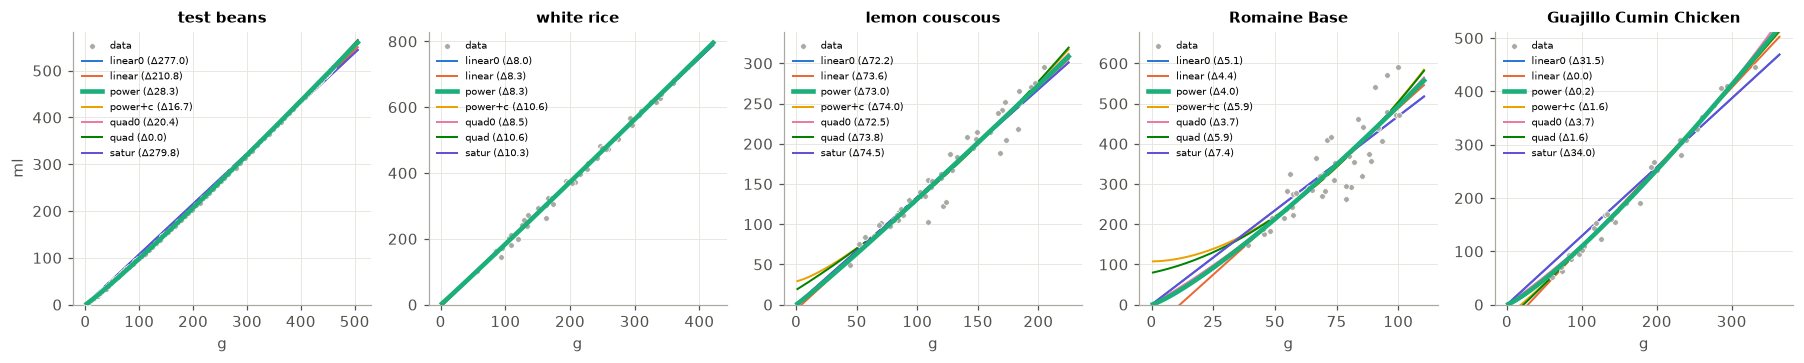

In [10]:
fig, axes = plt.subplots(1, len(ingredients), figsize=(3.3 * len(ingredients), 3.4), squeeze=False)
for ax, name in zip(axes[0], ingredients):
    g, y, s, labels = ingredient_data(name)
    gg = np.linspace(0, g.max() * 1.1, 200)[1:]
    zero = np.zeros(len(gg), int)
    ax.scatter(g, y, s=14, color=MUTED, edgecolor="white", linewidth=0.5, zorder=3, label="data")
    r = res[res.ingredient == name].set_index("model")
    for i, m in enumerate(m for m in MODELS if m not in SESSION_MODELS):
        pred = predict(m, r.loc[m, "q"], r.loc[m, "beta"], gg, zero, len(labels))
        ax.plot(gg, pred, color=SERIES[i], lw=3 if m == "power" else 1.3,
                label=f"{m} (Δ{r.loc[m, 'dAICc']:.1f})", zorder=4 if m == "power" else 2)
    ax.set_title(name)
    ax.set_xlabel("g")
    ax.set_ylim(0, y.max() * 1.15)
    ax.legend(fontsize=6.5, loc="upper left")
axes[0][0].set_ylabel("ml")
fig.tight_layout()

### Session models

Each session's points and its curve from `sess_scale`, where the sessions share p and each has its own K.
The table gives each session's K relative to the first session's: 0.85 means that session's food took 15 % less
volume per gram at the same shape. `Δ vs power` is how much AICc the session terms save over
plain `power`; more than about 4 is a real session effect.

ingredient,session,n,K_rel_first
white rice,20261007_3,13,1.000
white rice,20261019_1,35,1.022
lemon couscous,20261007,6,1.000
lemon couscous,20261009_2,41,1.251
Romaine Base,20261007_4,6,1.000
Romaine Base,20261009_1,36,1.190


model,Δ vs power: sess_offset,Δ vs power: sess_scale
ingredient,,
white rice,8.3,1.6
lemon couscous,73.0,69.6
Romaine Base,3.9,4.0


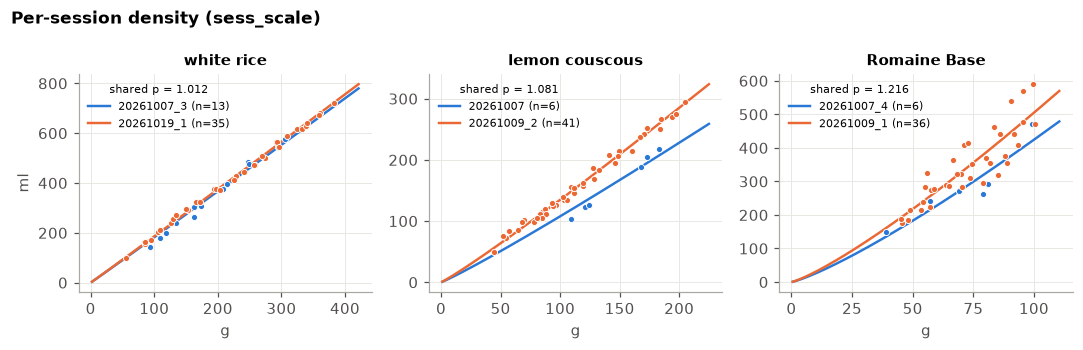

In [11]:
multi = [n for n in ingredients if summary.loc[n, "sessions"] > 1]
fig, axes = plt.subplots(1, len(multi), figsize=(3.3 * len(multi), 3.2), squeeze=False)
rows = []
for ax, name in zip(axes[0], multi):
    g, y, s, labels = ingredient_data(name)
    r = res[res.ingredient == name].set_index("model")
    sc = r.loc["sess_scale"]
    gg = np.linspace(0, g.max() * 1.1, 200)[1:]
    for j, lab in enumerate(labels):
        on = s == j
        ax.scatter(g[on], y[on], s=16, color=SERIES[j], edgecolor="white", linewidth=0.6, zorder=3)
        ax.plot(gg, predict("sess_scale", sc.q, sc.beta, gg, np.full(len(gg), j), len(labels)),
                color=SERIES[j], lw=1.6, label=f"{lab} (n={on.sum()})")
        rows.append({"ingredient": name, "session": lab, "n": int(on.sum()),
                     "K_rel_first": sc.beta[j] / sc.beta[0]})
    ax.set_title(name)
    ax.set_xlabel("g")
    ax.legend(fontsize=7, title=f"shared p = {sc.q:.3f}", title_fontsize=7)
axes[0][0].set_ylabel("ml")
fig.suptitle("Per-session density (sess_scale)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

sess = pd.DataFrame(rows)
power_aicc = res[res.model == "power"].set_index("ingredient").AICc
gain = (res[res.model.isin(SESSION_MODELS)]
        .pivot(index="ingredient", columns="model", values="AICc")
        .rsub(power_aicc, axis=0)               # power's AICc minus each session model's, row by row
        .loc[multi])
display(sess.style.hide(axis="index").format({"K_rel_first": "{:.3f}"}))
gain.add_prefix("Δ vs power: ").style.format("{:.1f}")

## 5. One model for every ingredient

The app uses a single curve family, with each ingredient fitting its own parameters. Because the
ingredients are fitted independently, their log-likelihoods add, so summed AICc and BIC compare
whole families. The calibration reference is left out here, since it isn't a food and with 82
very tight points it would decide the total by itself.

In [12]:
foods = res[~res.ingredient.map(summary.reference)]
fam = foods.groupby("model").agg(AICc=("AICc", "sum"), BIC=("BIC", "sum"))
fam["dAICc"] = fam.AICc - fam.AICc.min()
fam["dBIC"] = fam.BIC - fam.BIC.min()
best = foods.loc[foods.groupby("ingredient").AICc.idxmin()]
fam["best_for"] = best.groupby("model").ingredient.agg(", ".join)
fam["best_for"] = fam.best_for.fillna("")
fam.sort_values("dAICc")[["dAICc", "dBIC", "best_for"]].style.format({"dAICc": "{:.2f}", "dBIC": "{:.2f}"})

,dAICc,dBIC,best_for
model,,,
sess_offset,0.00,0.00,"lemon couscous, white rice"
sess_scale,10.03,10.03,Romaine Base
power,85.17,80.94,
linear,86.02,81.79,Guajillo Cumin Chicken
quad0,88.11,83.88,
quad,91.70,92.54,
power+c,91.89,92.73,
linear0,116.54,106.72,
satur,125.97,121.74,


## 6. Is constant error SD on ml a fair assumption?

The app's README says curves are fitted "on the volume itself, so a few ml of camera error weighs the
same at 20 g as at 400 g." That holds if the scatter really is constant. An alternative is
**multiplicative** error, where scatter grows with portion size; that is the same as least squares in log-log space.
Both are scored for the power law on the ml scale: the log-space likelihood gets the Jacobian −Σ log y,
so the two AICs are directly comparable and both models have the same k.

,n,AIC_mult_minus_add,resid_SD_small_half,resid_SD_large_half,p_additive,p_loglog
ingredient,,,,,,
test beans,82,163.66,1.6,1.3,1.07,1.06
white rice,48,29.75,15.4,9.3,1.02,1.02
lemon couscous,47,-2.44,10.5,18.6,1.05,1.02
Romaine Base,42,-11.08,33.9,64.6,1.22,1.18
Guajillo Cumin Chicken,32,3.73,11.5,13.4,1.21,1.25


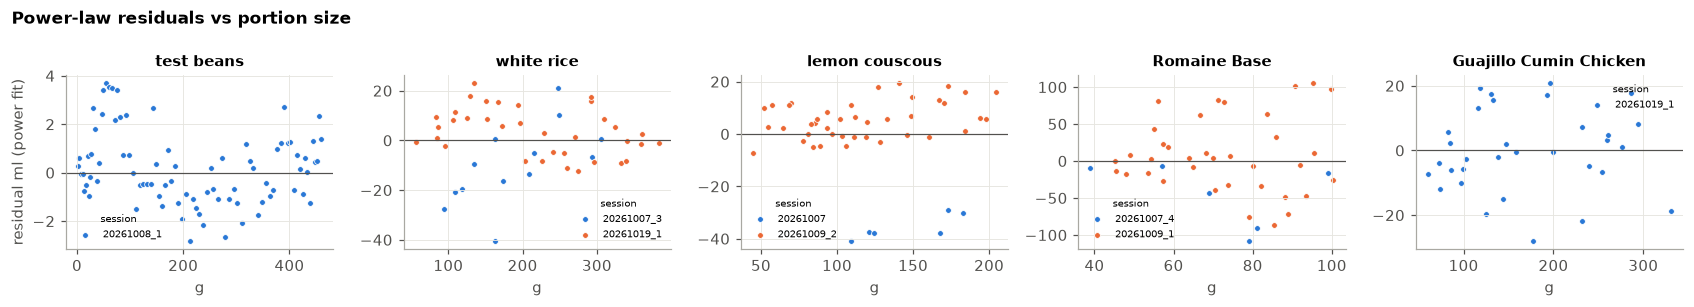

In [13]:
rows = []
fig, axes = plt.subplots(1, len(ingredients), figsize=(3.1 * len(ingredients), 2.8), squeeze=False)
for ax, name in zip(axes[0], ingredients):
    g, y, s, labels = ingredient_data(name)
    n = len(y)
    p, beta, rss, _ = fit("power", g, y, s, len(labels))
    ll_add = -0.5 * n * (math.log(2 * math.pi * rss / n) + 1)
    A = np.c_[np.ones(n), np.log(g)]
    beta_log, rss_log = lstsq(A, np.log(y))
    ll_mul = -0.5 * n * (math.log(2 * math.pi * rss_log / n) + 1) - float(np.sum(np.log(y)))
    resid = y - predict("power", p, beta, g, s, len(labels))
    small = g < np.median(g)
    rows.append({"ingredient": name, "n": n,
                 "AIC_mult_minus_add": 2 * (ll_add - ll_mul),
                 "resid_SD_small_half": resid[small].std(), "resid_SD_large_half": resid[~small].std(),
                 "p_additive": p, "p_loglog": beta_log[1]})
    ax.axhline(0, color=INK2, lw=0.8)
    for j, lab in enumerate(labels):
        on = s == j
        ax.scatter(g[on], resid[on], s=14, color=SERIES[j], edgecolor="white", linewidth=0.5, label=lab)
    ax.set_title(name)
    ax.set_xlabel("g")
    ax.legend(fontsize=6.5, title="session", title_fontsize=6.5)
axes[0][0].set_ylabel("residual ml (power fit)")
fig.suptitle("Power-law residuals vs portion size", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

err = pd.DataFrame(rows).set_index("ingredient")
err.style.format("{:.2f}", subset=["AIC_mult_minus_add", "p_additive", "p_loglog"]).format(
    "{:.1f}", subset=["resid_SD_small_half", "resid_SD_large_half"])

A negative `AIC_mult_minus_add` favours multiplicative error, i.e. scatter that grows with portion size.
Compare `p_additive` with `p_loglog` to see how much the choice of error model moves the fitted exponent.
The residuals are coloured by session: a session sitting entirely above or below zero is the session effect from section 4.

## 7. Mixed bowls: an out-of-sample check, and how much they squash

The app fits curves only from single-ingredient bowls; mixed bowls go to the squash fit. They can also
**check** the curves, because the curves never saw them. If volumes simply add, a two-ingredient bowl should
scan at about f_bottom(g_bottom) + f_top(g_top). Whatever is left over is squash, nesting
(the top layer settling into gaps in the bottom one), or a curve that's wrong.

Each mixed bowl is predicted with the curves **from its own day** (`sess_scale`: shared p, per-session K), because
section 4 showed the day matters. Column order in a sheet is dispense order, so the first ingredient is the bottom
layer. Rows go through the same rules as before (camera zero, `scale_g`, no cups).

Note what the app does now: `simulator.cc` only compresses a layer whose curve has **p < 1**, and every curve
here has p ≥ 1. So the current squash model has nothing to act on and predicts these bowls as purely additive.

In [14]:
def two_layer_rows(df, file):
    # Same reading rules as curve_points, keeping rows with exactly two ingredients.
    num = lambda col: pd.to_numeric(col, errors="coerce")
    df = df.rename(columns=str.strip)
    cols = {c.lower(): c for c in df.columns}
    ing_cols = [c for c in df.columns if c.lower() not in META]
    grams = df[ing_cols].apply(num).where(lambda x: x > 0)
    ml = num(df[cols["ml"]]) - EMPTY_BOWL_ML
    cups = num(df[cols["cups"]]).fillna(0) if "cups" in cols else 0
    scale_col = next((cols[c] for c in SCALE_COLS if c in cols), None)
    if scale_col:
        scale = num(df[scale_col])
        grams = grams.mul((scale / grams.sum(axis=1)).where(scale > 0, 1.0), axis=0)
    keep = (grams.notna().sum(axis=1) == 2) & (ml > 0) & (cups <= 0)
    out = []
    for i in df.index[keep]:
        (bot, gb), (top, gt) = grams.loc[i].dropna().items()   # column order = dispense order
        out.append({"file": file, "line": i + 2, "bottom": clean_name(bot), "g_bot": gb,
                    "top": clean_name(top), "g_top": gt, "ml": ml[i]})
    return pd.DataFrame(out)

mix = pd.concat([two_layer_rows(pd.read_csv(p, skip_blank_lines=False), os.path.basename(p))
                 for p in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
                 if not os.path.basename(p).startswith(".")], ignore_index=True)
spelling = dict(zip(pts.ingredient.str.lower(), pts.ingredient))
has_curve = mix.bottom.str.lower().isin(spelling) & mix.top.str.lower().isin(spelling)
if (~has_curve).any():
    print("skipped, no single-ingredient curve for a layer:",
          (mix.bottom + " + " + mix.top)[~has_curve].value_counts().to_dict())
mix = mix[has_curve].copy()
mix["bottom"] = mix.bottom.str.lower().map(spelling)
mix["top"] = mix.top.str.lower().map(spelling)
mix["pair"] = mix.bottom + " + " + mix.top
mix["date"] = mix.file.str.extract(r"(\d{8})")[0]

def day_curve(name, date):
    # The ingredient's sess_scale curve for the session on `date` -> (K, p, session label)
    g, y, s, labels = ingredient_data(name)
    p, beta, _, _ = fit("sess_scale", g, y, s, len(labels))
    j = next(j for j, lab in enumerate(labels) if lab.startswith(date))
    return beta[j], p, labels[j]

for side in ("bot", "top"):
    name_col = "bottom" if side == "bot" else "top"
    curves = [day_curve(n, d) for n, d in zip(mix[name_col], mix.date)]
    mix[f"v_{side}"] = [K * g ** p for (K, p, _), g in zip(curves, mix[f"g_{side}"])]
    mix[f"curve_{side}"] = [lab for _, _, lab in curves]
mix["resid"] = mix.ml - mix.v_bot - mix.v_top

(mix.groupby("pair")
    .agg(n=("ml", "size"), date=("date", "first"), bottom_curve=("curve_bot", "first"), top_curve=("curve_top", "first"),
         mean_resid_ml=("resid", "mean"), sd_resid_ml=("resid", "std"),
         mean_resid_pct=("resid", lambda r: 100 * (r / mix.loc[r.index, "ml"]).mean()))
    .style.format(precision=1))

,n,date,bottom_curve,top_curve,mean_resid_ml,sd_resid_ml,mean_resid_pct
pair,,,,,,,
Romaine Base + Chicken Al Pastor,6,20261007,20261007_4,20261007_4,17.6,10.0,4.3
Romaine Base + lemon couscous,30,20261009,20261009_1,20261009_2,-33.9,46.0,-5.7
Romaine Base + white rice,6,20261007,20261007_4,20261007_3,-3.3,42.5,-0.6
white rice + Guajillo Cumin Chicken,10,20261019,20261019_1,20261019_1,-11.8,8.8,-1.5


A negative residual means the bowl scanned **smaller** than its two curves add up to. Five one-parameter
explanations for the residual, each fitted on top of the fixed curves and compared by AICc within each pair:

| Term | Meaning |
|---|---|
| additive | no parameters: the curves just add |
| + c | a constant shift, e.g. a camera offset that day |
| bottom × α | the bottom layer takes a fixed fraction α of its single-portion volume once covered (nesting, settling) |
| top × α | the same for the top layer |
| − λ·g_top | the bottom loses volume in proportion to the weight on it (load-driven squash, the app's idea) |
| − μ·g_bot·g_top/100 | loss grows with both layers (more surface to interpenetrate) |

In [15]:
def aicc_gauss(rss, n, k_mean):
    k = k_mean + 1
    ll = -0.5 * n * (math.log(2 * math.pi * rss / n) + 1)
    return 2 * k - 2 * ll + 2 * k * (k + 1) / (n - k - 1)

def one_param(target, x):
    # least squares of target = b·x -> (b, rss)
    b = float(np.sum(target * x) / np.sum(x * x))
    return b, float(np.sum((target - b * x) ** 2))

rows = []
for pair, d in mix.groupby("pair"):
    y, vb, vt, gb, gt = (d[c].to_numpy() for c in ["ml", "v_bot", "v_top", "g_bot", "g_top"])
    r0 = y - vb - vt
    terms = {
        "additive": (None, float(np.sum(r0 ** 2)), 0),
        "+ c": (*one_param(r0, np.ones_like(r0)), 1),
        "bottom × α": (*one_param(y - vt, vb), 1),
        "top × α": (*one_param(y - vb, vt), 1),
        "− λ·g_top": (*one_param(-r0, gt), 1),
        "− μ·g_bot·g_top/100": (*one_param(-r0, gb * gt / 100), 1),
    }
    for term, (b, rss, k) in terms.items():
        rows.append({"pair": pair, "n": len(y), "term": term, "value": b,
                     "AICc": aicc_gauss(rss, len(y), k), "RMSE": math.sqrt(rss / len(y))})
sq = pd.DataFrame(rows)
sq["dAICc"] = sq.AICc - sq.groupby("pair").AICc.transform("min")
(sq.sort_values(["pair", "dAICc"])
   .set_index(["pair", "term"])[["n", "value", "dAICc", "RMSE"]]
   .style.format({"value": "{:.3f}", "dAICc": "{:.2f}", "RMSE": "{:.1f}"}, na_rep=""))

### Using mixed bowls to fit a curve

Each mixed bowl also gives an **implied point** for one layer: measured ml minus the other layer's curve.
Below, the implied bottom-layer volumes are plotted against that layer's single-portion curve for its day.
Points that sit on the curve mean that layer behaves in a bowl as it does alone. A consistent shortfall is the
`bottom × α` effect, drawn dashed. This is also how mixed bowls could feed a curve fit: a joint fit of
single-ingredient and mixed rows, with α as one extra parameter.

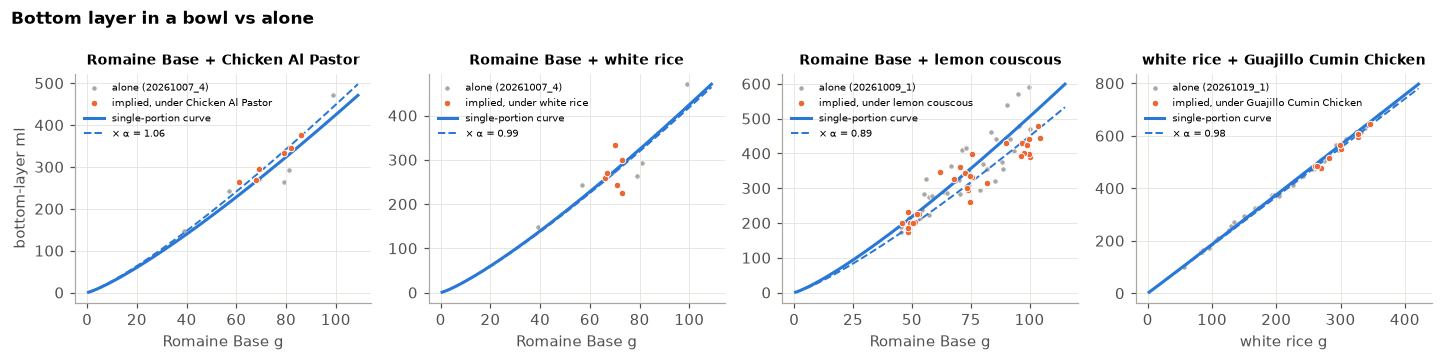

In [16]:
pairs = mix.pair.unique().tolist()
fig, axes = plt.subplots(1, len(pairs), figsize=(3.3 * len(pairs), 3.3), squeeze=False)
for ax, pair in zip(axes[0], pairs):
    d = mix[mix.pair == pair]
    K, p, lab = day_curve(d.bottom.iloc[0], d.date.iloc[0])
    single = pts[(pts.ingredient == d.bottom.iloc[0]) & (pts.session == lab)]
    gg = np.linspace(0, max(d.g_bot.max(), single.g.max()) * 1.1, 200)[1:]
    alpha = sq[(sq.pair == pair) & (sq.term == "bottom × α")].value.iloc[0]
    ax.scatter(single.g, single.ml, s=12, color=MUTED, edgecolor="white", linewidth=0.5, label=f"alone ({lab})")
    ax.scatter(d.g_bot, d.ml - d.v_top, s=18, color=SERIES[1], edgecolor="white", linewidth=0.6,
               label=f"implied, under {d.top.iloc[0]}", zorder=3)
    ax.plot(gg, K * gg ** p, color=SERIES[0], lw=2, label="single-portion curve")
    ax.plot(gg, alpha * K * gg ** p, color=SERIES[0], lw=1.3, ls="--", label=f"× α = {alpha:.2f}")
    ax.set_title(pair, fontsize=9)
    ax.set_xlabel(f"{d.bottom.iloc[0]} g")
    ax.legend(fontsize=6.5, loc="upper left")
axes[0][0].set_ylabel("bottom-layer ml")
fig.suptitle("Bottom layer in a bowl vs alone", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

## 8. Reading the results (data as of 2026-10-20)

*These notes describe the data when the notebook was written. Rerun all cells after adding measurements.*

**The largest effect in the data is a shift between sessions, not curve shape.**

- For white rice, lemon couscous and Romaine, letting each session have its own offset or density beats every
  single-curve model: by about 8, 73 and 4 AICc over `power`. Summed over foods, `sess_offset` beats `power` by about 85.
- **In every case the low session is a 10/07 file** (`20261007`, `20261007_3`, `20261007_4`). That is 6 points for
  couscous and Romaine and 13 for rice. Under `sess_scale` the later sessions read about 2 %, 25 % and 19 % more
  volume per gram. Couscous and Romaine are far too big to be noise. One cause behind all three (camera setup,
  empty-bowl zero or bowl type that day) is more likely than three different batch densities.
- `sess_offset` (a fixed ml shift) is slightly ahead of `sess_scale` for rice and couscous, which points toward a
  measurement shift rather than the food. But each 10/07 session is small, so the two can't be cleanly separated.
- **The session effect distorts the shape estimates.** Fitted with session offsets, couscous and Romaine come out
  at p ≈ 1.4; fitted with a single curve, they come out at p ≈ 1.05–1.2. Settle the 10/07 question before reading
  much into p.

**On shape alone**, as in the earlier version of this notebook:

- Across all foods, `power` and `linear` (a + b·g) are within about 1 AICc. No 3-parameter shape earns its
  extra parameter, and `satur` runs to its bound (a straight line), so there's no sign of compression.
- Guajillo chicken, a single session, is the one food that clearly needs more than constant density (`linear0` +31 AICc).
- Romaine's scatter also grows with portion size (multiplicative error favoured by 11 AIC).
- The calibration reference (test beans) prefers a slightly curved `quad`. The camera seems to read a little high
  at larger volumes, which the app's Backfill option corrects.

**Mixed bowls (section 7)**, each predicted from its own day's curves, which never saw them:

- **The curves mostly add up.** Rice + Guajillo scans 12 ml (1.5 %) below the sum, with residual SD ≈ 9 ml, about
  the same as the single curves themselves. Romaine + rice (10/07) is additive to within 3 ml.
- **The 10/07 mixed bowls agree with the 10/07 single bowls.** That supports the idea that something about the
  whole day read low (setup or camera), rather than the curves being wrong.
- **Romaine + couscous, the best set (30 bowls on a 3 × 5 grid), scans 34 ml (5.7 %) below the sum.** The best
  explanation is that covered Romaine takes about 89 % of its alone volume (`bottom × α`), whatever is on top.
  Loss in proportion to the weight on top (`− λ·g_top`, the app's load idea) is 8 AICc worse. This looks like
  settling or nesting, not load-driven squash.
- **Covered Romaine scatters much less than Romaine alone.** Much of the single curve's ±50 ml is probably loose
  leaves the camera sees from above, and it disappears once something is on top.
- **The app's squash model can't represent any of this**: it only compresses curves with p < 1, and none have
  one. A fixed "covered" factor per base would capture what the data show.

**Next step:** find out what was different on 10/07. If that setup is gone, move those files to `data/archive/`
and rerun. The single-curve comparison will then be done on consistent data.
- Ingredients with fewer than `MIN_N` points are listed in the summary table but not compared.

## 9. Lab lunch bowls (BB-0101, 2026-10-19)

48 real lunch bowls from `data/archive/bowl_data_20261019_2.csv`. **These bowls were lidded before they were scanned** (lid on → weigh → lid off → scan). The simulator predicts volume *before* lidding, so this sheet is archived: the app doesn't load it, and section 10 doesn't use it. It stays here as background on what the lid does. Each has a camera scan, a tared bench-scale weight (`scale_g`),
and the robot's per-ingredient grams from `catalog_metrics.product_dispense_metrics`. Layers in dispense order:

| Layer | Grams | Curve used |
|---|---|---|
| White Rice (bottom) | ~250, nearly constant | white rice, 10/19 session |
| Chicken Tex-Mex | 150–227 | **Guajillo Cumin Chicken, 10/19 session**: same prep (thigh, 1-inch cubes), different spices |
| Romaine Chop (top) | ~30 or none | none: fitted here as free ml/g, since it sits on top rather than as a base |
| Cheese (top) | ~30–58 or none | none: fitted here as free ml/g |

The same rules as everywhere else apply: grams rescaled to `scale_g`, and ml corrected by the empty-bowl reading.
No sauce cups were recorded for these scans.

The question for squash: with rice and chicken on their own curves, do the bowls scan at the sum, or below it?
The same squash terms as section 7 are compared. Here they absorb the gap between measured ml and
rice + chicken + (free toppings).

In [17]:
ARCHIVE_DIR = "data/archive"      # lidded bowls: kept out of data/measurements and the pre-lid model
LUNCH_FILE = "bowl_data_20261019_2.csv"
LAYERS = {"White Rice": "rice_g", "Chicken Tex-Mex": "chicken_g", "Romaine Chop": "romaine_g", "Cheese": "cheese_g"}

lunch = pd.read_csv(os.path.join(ARCHIVE_DIR, LUNCH_FILE))
grams = lunch[list(LAYERS)].fillna(0)
grams = grams.mul(lunch.scale_g / grams.sum(axis=1), axis=0)     # trust the bench-scale total
lunch = pd.concat([lunch, grams.rename(columns=LAYERS)], axis=1)
lunch["ml_c"] = lunch.ml - EMPTY_BOWL_ML
lunch["order"] = lunch.notes.str.extract(r"order (D-\d+)")[0]
lunch["toppings"] = np.select(
    [(lunch.romaine_g > 0) & (lunch.cheese_g > 0), lunch.romaine_g > 0, lunch.cheese_g > 0],
    ["romaine + cheese", "romaine only", "cheese only"], "none")

K_rice, p_rice, _ = day_curve("white rice", "20261019")
K_chk, p_chk, _ = day_curve("Guajillo Cumin Chicken", "20261019")
lunch["v_rice"] = K_rice * lunch.rice_g ** p_rice
lunch["v_chk"] = K_chk * lunch.chicken_g ** p_chk

(lunch.groupby("toppings")
      .agg(n=("ml_c", "size"), ml=("ml_c", "mean"), ml_sd=("ml_c", "std"), rice_g=("rice_g", "mean"),
           chicken_g=("chicken_g", "mean"), romaine_g=("romaine_g", "mean"), cheese_g=("cheese_g", "mean"),
           rice_plus_chicken_curves=("v_rice", lambda s: (s + lunch.loc[s.index, "v_chk"]).mean()))
      .style.format(precision=1))

,n,ml,ml_sd,rice_g,chicken_g,romaine_g,cheese_g,rice_plus_chicken_curves
toppings,,,,,,,,
cheese only,9,710.0,38.7,252.2,179.2,0.0,36.4,695.6
none,2,618.5,2.1,254.2,165.8,0.0,0.0,679.3
romaine + cheese,33,948.2,44.4,253.0,184.8,30.3,32.3,705.6
romaine only,4,889.5,54.5,254.8,187.5,30.6,0.0,713.0


In [18]:
def ols(target, X):
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    r = target - X @ beta
    se = np.sqrt(np.diag(r @ r / (len(r) - X.shape[1]) * np.linalg.inv(X.T @ X)))
    return beta, se, float(r @ r)

y, n = lunch.ml_c.to_numpy(), len(lunch)
vr, vc = lunch.v_rice.to_numpy(), lunch.v_chk.to_numpy()
tops = lunch[["romaine_g", "cheese_g"]].to_numpy()                 # free ml/g for each topping
load_on_rice = (lunch.chicken_g + lunch.romaine_g + lunch.cheese_g).to_numpy()

# squash term -> (target, extra column or None, how to read the parameter)
SQUASH = {
    "additive":               (y - vr - vc, None, ""),
    "+ c":                    (y - vr - vc, np.ones(n), "ml shift"),
    "chicken × α":            (y - vr, vc, "chicken's share of its alone volume"),
    "rice × α":               (y - vc, vr, "rice's share of its alone volume"),
    "− λ·(weight on rice)":   (y - vr - vc, -load_on_rice, "ml lost per g sitting on the rice"),
    "− μ·g_rice·g_chk/100":   (y - vr - vc, -lunch.rice_g.to_numpy() * lunch.chicken_g.to_numpy() / 100, ""),
}
rows, preds = [], {}
for term, (target, x, meaning) in SQUASH.items():
    X = tops if x is None else np.c_[x, tops]
    beta, se, rss = ols(target, X)
    preds[term] = y - (target - X @ beta)
    rows.append({"term": term, "param": None if x is None else beta[0], "± se": None if x is None else se[0],
                 "reads as": meaning, "romaine ml/g": beta[-2], "cheese ml/g": beta[-1],
                 "AICc": aicc_gauss(rss, n, X.shape[1]), "RMSE": math.sqrt(rss / n)})
lunch_sq = pd.DataFrame(rows)
lunch_sq["dAICc"] = lunch_sq.AICc - lunch_sq.AICc.min()

alpha = lunch_sq.set_index("term").loc["chicken × α"]
lost = (1 - alpha.param) * vc
stand = mix.loc[mix.pair == "white rice + Guajillo Cumin Chicken", "resid"]
print(f"chicken × α = {alpha.param:.3f} ± {alpha['± se']:.3f}: rice + chicken scans {lost.mean():.0f} ml below the curves "
      f"({100 * (lost / (vr + vc)).mean():.1f}% of rice + chicken)")
print(f"same pairing on the BB-0010 test stand, same day (section 7): {stand.mean():.0f} ml "
      f"({100 * (stand / mix.loc[stand.index, 'ml']).mean():.1f}%) over {len(stand)} bowls")
(lunch_sq.sort_values("dAICc")[["term", "param", "± se", "reads as", "romaine ml/g", "cheese ml/g", "dAICc", "RMSE"]]
    .style.hide(axis="index")
    .format({"param": "{:.3f}", "± se": "{:.3f}", "romaine ml/g": "{:.2f}", "cheese ml/g": "{:.2f}",
             "dAICc": "{:.2f}", "RMSE": "{:.1f}"}, na_rep=""))

chicken × α = 0.754 ± 0.065: rice + chicken scans 56 ml below the curves (7.9% of rice + chicken)
same pairing on the BB-0010 test stand, same day (section 7): -12 ml (-1.5%) over 10 bowls


term,param,± se,reads as,romaine ml/g,cheese ml/g,dAICc,RMSE
− λ·(weight on rice),0.313,0.081,ml lost per g sitting on the rice,8.01,2.36,0.00,31.8
− μ·g_rice·g_chk/100,0.124,0.032,,7.70,2.04,0.24,31.8
chicken × α,0.754,0.065,chicken's share of its alone volume,7.68,2.01,0.28,31.9
+ c,-56.627,15.115,ml shift,7.64,2.06,0.65,32.0
rice × α,0.883,0.032,rice's share of its alone volume,7.63,2.04,1.04,32.1
additive,,,,6.82,0.96,11.30,36.6


In [19]:
# Romaine Chop on top vs the Romaine Base curve measured alone (10/09)
K_rom, p_rom, _ = day_curve("Romaine Base", "20261009")
rom = lunch_sq.set_index("term").loc["chicken × α", "romaine ml/g"]
g30 = lunch.loc[lunch.romaine_g > 0, "romaine_g"].mean()
print(f"Romaine Chop on top: {rom:.2f} ml/g → {rom * g30:.0f} ml for the average {g30:.0f} g")
print(f"Romaine Base alone at {g30:.0f} g: {K_rom * g30 ** p_rom:.0f} ml ({K_rom * g30 ** p_rom / g30:.2f} ml/g)")
print(f"lid failures: {int((lunch.lid == 'failed').sum())} of {n}, "
      f"all in bowls with romaine: {set(lunch.loc[lunch.lid == 'failed', 'toppings'])}")

Romaine Chop on top: 7.68 ml/g → 233 ml for the average 30 g
Romaine Base alone at 30 g: 118 ml (3.90 ml/g)
lid failures: 6 of 48, all in bowls with romaine: {'romaine + cheese'}


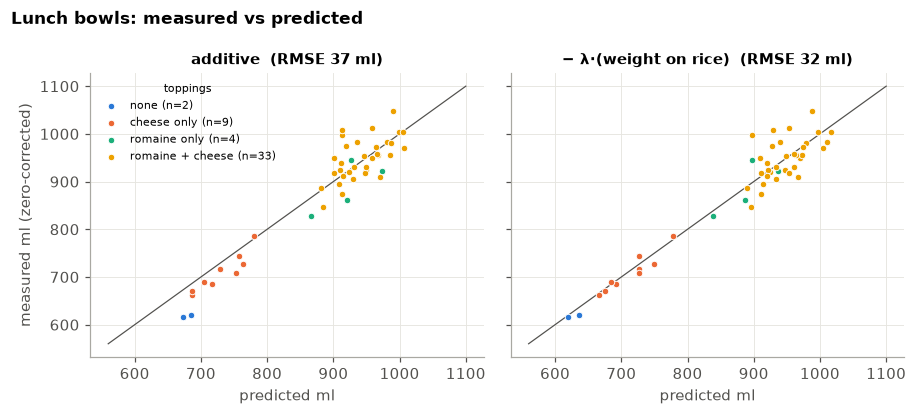

In [20]:
best = lunch_sq.sort_values("dAICc").term.iloc[0]
groups = ["none", "cheese only", "romaine only", "romaine + cheese"]
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8), sharex=True, sharey=True)
for ax, term in zip(axes, ["additive", best]):
    for i, grp in enumerate(groups):
        on = (lunch.toppings == grp).to_numpy()
        ax.scatter(preds[term][on], y[on], s=18, color=SERIES[i], edgecolor="white", linewidth=0.6,
                   label=f"{grp} (n={on.sum()})", zorder=3)
    lo, hi = 560, 1100
    ax.plot([lo, hi], [lo, hi], color=INK2, lw=0.8)
    rmse = lunch_sq.set_index("term").loc[term, "RMSE"]
    ax.set_title(f"{term}  (RMSE {rmse:.0f} ml)")
    ax.set_xlabel("predicted ml")
axes[0].set_ylabel("measured ml (zero-corrected)")
axes[0].legend(fontsize=7, title="toppings", title_fontsize=7)
fig.suptitle("Lunch bowls: measured vs predicted", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

### Reading the lunch bowls

*Numbers as of 2026-10-20; rerun after adding bowls.*

- **The lunch bowls squash; the test stand barely did.** With rice and chicken on their 10/19 curves, every squash term
  beats "additive" by about 11 AICc. Rice + chicken scans about **56 ml (8 %)** below the curves, versus 12 ml (1.5 %)
  for the same pairing on the BB-0010 test stand that day. The two rice + chicken-only bowls (D-020, D-032) show it
  without any topping assumptions: 617 and 620 ml scanned against 673 and 686 ml predicted.
- **This data can't separate the squash forms** (all within about 1 AICc). Rice is about 250 g in every bowl, and the
  weight on the rice moves in step with the chicken weight. The load form reads as about 0.31 ml lost per gram sitting
  on the rice. Varying the rice portion would separate the forms.
- **Most of the difference is the lid.** Only these lunch bowls were ever lidded (lid on → weigh → lid off → scan).
  The 10/19 test-stand bowls (`bowl_data_20261019_1`) were never lidded, and were measured right after lunch from the
  **same rice and chicken batch**. Batch therefore cancels, and with robot differences ignored for now, the lid
  accounts for about **6.4 ± 2.2 points** of rice + chicken volume, roughly 45 ml on a ~700 ml base. Rice and chicken
  stay compressed after the lid comes off.
- **Still open:** whether lid compression grows with how far the food rises above the lid line, and the BB-0101 vs
  BB-0010 drop height. Scanning each bowl before and after lidding at the next lunch measures the lid directly.
- **Romaine Chop on top scans at about 2× its volume alone**: about 7.7 ml/g, so roughly 230 ml for 30 g, against 118 ml
  from the Romaine Base curve. Under couscous (section 7), Romaine scanned at 0.89×. Position matters more than mass: the
  camera sees the top surface, and leaves over a mound lift all of it. Some ten Romaine Chop portions scanned alone would
  rule out a difference between the two romaine products.
- **Cheese on top adds about 2 ml/g**, about 65 ml for 30 g.
- **Lid failures** (6 bowls, all with Romaine) didn't change the scan noticeably.
- **The app currently predicts these bowls as purely additive** (no curve has p < 1), so it would over-predict
  rice + chicken by about 8 % and under-predict a Romaine topping by about half.

## 10. A hierarchical Bayesian version of the curves

Same physics as before (a power law per ingredient), fitted so that ingredients and batches **share information**
instead of each being fitted alone. Only single-ingredient bowls are used here, all unlidded. The calibration
reference (test beans) is left out.

**The model.** For bowl *j* of ingredient *i* from batch *s*:

$$\text{ml}_j \sim \text{Normal}\Big(A_i \, e^{b_s} \, (g_j/100)^{p_i},\ \sigma_i\Big)$$

| Piece | Meaning | Shared how |
|---|---|---|
| $A_i$ | ml of a typical batch at 100 g | $\log A_i \sim \text{Normal}(\mu_{A,\text{kind}},\ \tau_A)$: ingredients of a kind (base, protein, topping) share a typical size |
| $p_i$ | the exponent, the curve's shape | $p_i \sim \text{Normal}(\mu_p,\ \tau_p)$: all ingredients share a typical shape |
| $b_s$ | batch (session) shift, on the log scale | $b_s \sim \text{Normal}(0,\ \tau_\text{batch})$: one spread shared by every batch of every ingredient |
| $\sigma_i$ | each ingredient's bowl-to-bowl scatter in ml | its own |

Writing the curve as $A\,(g/100)^p$ instead of $K\,g^p$ is the same curve. $A$ is easier to put a prior on
(ml at a 100 g portion), and it is much less tangled with $p$ when sampling.

**Partial pooling** is the point of the hierarchy. The model learns how much ingredients of a kind really differ
($\tau_A$, $\tau_p$). An ingredient with many points (white rice, 48) is pinned by its own data. One with 6 points
(Pico de Gallo) is pulled toward its kind, in proportion to how little its data say. The app's proxy and family
curves are a hand-written version of the same idea; here the amount of borrowing is estimated.

**Priors** (weak, on physical scales):
- typical size $\mu_A$: ~150 ml per 100 g, within a factor of ~2
- typical shape $\mu_p$: 1 ± 0.2
- spreads: $\tau_A \le$ ~0.5, $\tau_p \le$ ~0.15 and $\tau_\text{batch} \le$ ~0.15 on log scales (half-normal)
- scatter $\sigma_i$: half-normal with scale 40 ml

### How this model works, from scratch

#### The idea

**Least squares** (sections 2–4) finds the *one* curve that fits each ingredient's points best, and fits each ingredient
**on its own**: rice knows nothing about couscous, and Pico de Gallo's 6 points are all Pico has. You get one answer
(for example p = 1.94) and no sense of how far to trust it.

**Change 1: a range of plausible answers instead of one.** A Bayesian model hands back *every reasonably plausible
curve*, each weighted by how plausible it is. With 48 points (rice) they bunch tightly together; with 6 points over
29–53 g (Pico) they spread widely. That spread is the uncertainty, and it carries straight through to predictions.
A curve's plausibility multiplies two things:
1. how well it explains the data;
2. how reasonable it was before seeing the data (the **prior**: "p is probably near 1; p = 5 would be bizarre for food").

The result is the **posterior**: what's plausible once the data are weighed against prior expectations.

**Change 2: ingredients are related ("hierarchical").** Proteins have similar sizes; most foods have p around 1–1.3.
The model learns **the family and its members at the same time**: members' estimates tell it what the family looks like,
and the family pulls on members with little data of their own. This is **partial pooling**, and its strength is
automatic. Rice has so much data that the family barely matters; Pico has so little that the family dominates.
A restaurant with two 5-star reviews isn't really better than one with 500 reviews averaging 4.6; a sensible guess for
the first sits near "typical restaurant". Partial pooling makes that adjustment, and the data decide how strongly.
Batches work the same way: each batch can shift volume up or down, and all batches share one learned "typical shift
size". An ingredient measured on one day still inherits that variability when predicting a *new* batch.

#### The math, every symbol defined

**Notation**
- *i* = ingredient, *s* = batch (session, e.g. "white rice | 20261019_1"), *j* = one bowl (one row of data)
- $g_j$ = grams in bowl *j*; $\text{ml}_j$ = its scanned volume
- "~" reads "is drawn from"
- **Normal(center, spread)** = a bell curve: values near the center are likely, and the spread (a standard deviation) sets how wide it is
- **HalfNormal(scale)** = the positive half of a bell curve at 0, for things that must be positive
- **log / e** = natural log and its inverse. On a log scale, "×1.15" becomes "+0.14".

**Layer 1: the curve (the physics)**

$$\text{expected ml} = A_i \cdot (g/100)^{p_i} \cdot e^{b_s}$$

- $A_i$ = ml taken up by 100 g of ingredient *i*, typical batch (the app's K rescaled: $K = A/100^p$)
- $p_i$ = ingredient *i*'s exponent, the curve's shape (1 = constant density)
- $b_s$ = batch *s*'s shift on the log scale. Volume is multiplied by $e^{b_s}$: +0.10 → ×1.105, −0.12 → ×0.89, 0 → a typical batch.

**Layer 2: the data (the "likelihood")**

$$\text{ml}_j \sim \text{Normal}(\text{expected ml for bowl } j,\ \sigma_i)$$

- $\sigma_i$ (**sigma**) = **bowl-to-bowl scatter** for ingredient *i*, in ml (about ±13 ml for rice, about ±50 ml for Romaine).
  This line scores how well candidate parameters explain each point, measured in units of σ.

**Layer 3: the family (the hierarchy)**

$$\log A_i \sim \text{Normal}(\mu_{A,\text{kind}},\ \tau_A) \qquad p_i \sim \text{Normal}(\mu_p,\ \tau_p) \qquad b_s \sim \text{Normal}(0,\ \tau_\text{batch})$$

- $\mu$ (**mu**) = a group's **center**, its typical value: $\mu_{A,\text{kind}}$ is the typical log-size of a base, protein or topping; $\mu_p$ is the typical exponent across foods.
- $\tau$ (**tau**) = the **spread between group members**: $\tau_A$ is how much sizes vary within a kind, $\tau_p$ how much exponents vary between ingredients, $\tau_\text{batch}$ how much batches vary.
- **σ is not τ.** σ is scatter between *bowls*, in ml; τ is spread between *ingredients or batches*, in parameter units.
- μ and τ are **estimated from the data too**. Rice at 1.01, couscous 1.08, Romaine 1.18 and Guajillo 1.20 tell the model "exponents center around 1.15, give or take about 0.13". That learned family is what pulls on Pico.

**Layer 4: priors on the family (the "hyperpriors")**, deliberately vague, ruling out only the absurd:
$\mu_A \sim \text{Normal}(\log 150, 0.7)$ (about 150 ml per 100 g, within a factor of about 2);
$\mu_p \sim \text{Normal}(1, 0.2)$;
$\tau_A \sim \text{HalfNormal}(0.5)$, $\tau_p \sim \text{HalfNormal}(0.15)$, $\tau_\text{batch} \sim \text{HalfNormal}(0.15)$;
$\sigma_i \sim \text{HalfNormal}(40)$ (tens of ml, not thousands).

**Bayes' rule ties the layers together**

$$\text{plausibility}(\text{parameters} \mid \text{data}) \;\propto\; \text{likelihood}(\text{data} \mid \text{parameters}) \times \text{prior}(\text{parameters})$$

(∝ means "proportional to".) A full candidate set of A, p, b, μ, τ and σ is plausible if it explains the scans (layer 2)
*and* fits together sensibly (layers 3–4).

**Why sparse ingredients get pulled: the shrinkage formula.** In a simplified version, an ingredient's exponent is about
a weighted average of its own estimate and the family center:

$$p_\text{Bayes} \approx w \cdot p_\text{own} + (1 - w)\,\mu_p, \qquad w = \frac{1/se^2}{1/se^2 + 1/\tau_p^2}$$

*se* is the standard error of the ingredient's own estimate (large with few or narrowly spread points). With
$\tau_p \approx 0.13$ and $\mu_p \approx 1.15$:
- **Rice:** se ≈ 0.014, so w ≈ 0.99. It keeps its own estimate (1.019 → 1.014).
- **Pico:** se ≈ 0.5, so w ≈ 0.06: 0.06·1.94 + 0.94·1.15 ≈ 1.20. The model got 1.215.

Nobody sets those weights; they come from how much data each ingredient has and how different ingredients turn out to be.

**How the computer does it: sampling.** There is no closed-form answer, so PyMC uses **MCMC** (Markov chain Monte Carlo).
Its sampler, **NUTS**, explores parameter space and spends time in each region in proportion to its plausibility.
The output is **4,000 draws**; each is one complete, self-consistent set of parameters. The posterior mean is their
average, and a 94 % interval holds 94 % of them. The diagnostics check the sampler:
- **divergences**: places it got stuck or slipped; want 0
- **r̂** ("r-hat"): whether the 4 independent chains agree; want ≤ 1.01
- **ESS** (effective sample size): how many independent draws the 4,000 correlated ones are worth; want hundreds or more

The code writes $p = \mu_p + \tau_p z$ with $z \sim \text{Normal}(0, 1)$: the **non-centred** form, the same model
rearranged so the sampler explores more easily.

**How predictions work.** For "250 g rice + 180 g chicken from a new batch", the notebook takes each of the 4,000 draws, in turn:
1. computes each layer's curve with that draw's A and p;
2. draws a fresh batch shift $b \sim \text{Normal}(0, \tau_\text{batch})$, because nobody has measured that batch;
3. adds bowl scatter, drawn using σ;
4. records the total.

That gives 4,000 plausible volumes. The median, 80 % range and P(volume > fill line) are read straight off them, with
uncertainty about the curves, the batch and the bowl all included.

#### Symbol cheat sheet

| Symbol | Name | Meaning here | Units / scale |
|---|---|---|---|
| $A_i$ | – | ml at 100 g, ingredient *i*, typical batch | ml |
| $p_i$ | – | exponent (curve shape) | unitless, ~1 |
| $b_s$ | – | batch shift; multiplies volume by $e^b$ | log (0.1 ≈ +10 %) |
| $\sigma_i$ | sigma | bowl-to-bowl scatter | ml |
| $\mu_{A,\text{kind}}$ | mu | typical log-size for a kind | log ml |
| $\mu_p$ | mu | typical exponent | unitless |
| $\tau_A$ | tau | spread of sizes within a kind | log |
| $\tau_p$ | tau | spread of exponents between foods | unitless |
| $\tau_\text{batch}$ | tau | spread between batches | log (0.14 ≈ ±15 %) |
| $z$ | – | standard-normal helper (non-centred form) | unitless |


In [21]:
import warnings
import arviz as az
import pymc as pm

# Kind of each measured food. Add new ingredients here; the model will refuse to run without one.
KIND = {
    "white rice": "base", "lemon couscous": "base", "Romaine Base": "base",
    "Guajillo Cumin Chicken": "protein", "Suadero Beef": "protein", "Chicken Al Pastor": "protein",
    "Mexican Slaw": "topping", "Pico de Gallo": "topping", "Pineapple-Cucumber Salad": "topping",
}
foods = pts[~pts.reference].reset_index(drop=True)
missing = sorted(set(foods.ingredient) - set(KIND))
assert not missing, f"add these to KIND: {missing}"

ing_idx, ing_names = pd.factorize(foods.ingredient)
kind_idx, kinds = pd.factorize(pd.Series([KIND[n] for n in ing_names]))
batch_idx, batches = pd.factorize(foods.ingredient + " | " + foods.session)
x_obs = np.log(foods.g.to_numpy() / 100)
y_obs = foods.ml.to_numpy()

coords = {"kind": list(kinds), "ingredient": list(ing_names), "batch": list(batches)}
with pm.Model(coords=coords) as curve_model:
    # Non-centred form (mean + spread × standard normal) samples far better for hierarchies like this one.
    mu_logA = pm.Normal("mu_logA", np.log(150), 0.7, dims="kind")
    tau_A = pm.HalfNormal("tau_A", 0.5)
    logA = pm.Deterministic("logA", mu_logA[kind_idx] + tau_A * pm.Normal("z_A", 0, 1, dims="ingredient"),
                            dims="ingredient")
    mu_p = pm.Normal("mu_p", 1.0, 0.2)
    tau_p = pm.HalfNormal("tau_p", 0.15)
    p = pm.Deterministic("p", mu_p + tau_p * pm.Normal("z_p", 0, 1, dims="ingredient"), dims="ingredient")
    tau_batch = pm.HalfNormal("tau_batch", 0.15)
    b = pm.Deterministic("b", tau_batch * pm.Normal("z_b", 0, 1, dims="batch"), dims="batch")
    sigma = pm.HalfNormal("sigma", 40, dims="ingredient")

    mean_ml = pm.math.exp(logA[ing_idx] + b[batch_idx] + p[ing_idx] * x_obs)
    pm.Normal("ml", mean_ml, sigma[ing_idx], observed=y_obs)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        idata = pm.sample(1000, tune=1500, chains=4, target_accept=0.95, random_seed=37, progressbar=False)

post = idata.posterior.stack(sample=("chain", "draw"))
n_div = int(idata.sample_stats.diverging.sum())
diag = az.summary(idata, var_names=["mu_logA", "tau_A", "mu_p", "tau_p", "tau_batch", "logA", "p", "sigma"])
print(f"divergences: {n_div}   worst r_hat: {diag.r_hat.max():.3f}   smallest bulk ESS: {diag.ess_bulk.min():.0f}")
print("(want 0 divergences, r_hat ≤ 1.01, ESS in the hundreds or more)")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_logA, tau_A, z_A, mu_p, tau_p, z_p, tau_batch, z_b, sigma]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 41 seconds.


divergences: 0   worst r_hat: 1.010   smallest bulk ESS: 1348
(want 0 divergences, r_hat ≤ 1.01, ESS in the hundreds or more)


### What partial pooling did to each ingredient

Below, each ingredient's least-squares fit on its own (as in sections 2–4, pooled over sessions) is set beside the
Bayesian posterior, with mean and 94 % interval. $A_{100}$ is ml at 100 g for a typical batch.
Look at the 6-point ingredients: their exponents move toward the shared shape, and the intervals show how uncertain they still are.

In [22]:
def hdi(draws):
    lo, hi = az.hdi(np.asarray(draws), hdi_prob=0.94)
    return lo, hi

rows = []
for name in ing_names:
    g, yv, s, labels = ingredient_data(name)
    q, beta, _, _ = fit("power", g, yv, np.zeros(len(g), int), 1)
    A_draws = np.exp(post["logA"].sel(ingredient=name).values)
    p_draws = post["p"].sel(ingredient=name).values
    rows.append({"ingredient": name, "kind": KIND[name], "n": len(g), "sessions": len(labels),
                 "p (LS)": q, "p (Bayes)": p_draws.mean(), "p 94%": "{:.2f}–{:.2f}".format(*hdi(p_draws)),
                 "A100 (LS)": beta[0] * 100 ** q, "A100 (Bayes)": A_draws.mean(),
                 "A100 94%": "{:.0f}–{:.0f}".format(*hdi(A_draws)),
                 "scatter ml": post["sigma"].sel(ingredient=name).values.mean()})
pool = pd.DataFrame(rows).sort_values(["kind", "n"], ascending=[True, False])
pool.style.hide(axis="index").format({"p (LS)": "{:.3f}", "p (Bayes)": "{:.3f}", "A100 (LS)": "{:.0f}",
                                      "A100 (Bayes)": "{:.0f}", "scatter ml": "{:.1f}"})

ingredient,kind,n,sessions,p (LS),p (Bayes),p 94%,A100 (LS),A100 (Bayes),A100 94%,scatter ml
white rice,base,48,2,1.019,1.014,0.99–1.04,184,185,152–224,13.0
lemon couscous,base,47,2,1.054,1.082,1.04–1.12,131,124,100–152,7.5
Romaine Base,base,42,2,1.216,1.181,1.01–1.35,494,450,350–546,50.4
Guajillo Cumin Chicken,protein,32,1,1.209,1.204,1.15–1.26,109,111,83–142,13.5
Suadero Beef,protein,6,1,1.468,1.287,1.05–1.53,107,113,81–145,12.5
Chicken Al Pastor,protein,6,1,1.303,1.228,1.04–1.40,84,89,65–116,9.4
Mexican Slaw,topping,6,1,1.129,1.135,1.01–1.25,257,247,173–317,8.2
Pico de Gallo,topping,6,1,1.935,1.215,0.96–1.56,113,68,42–101,6.8
Pineapple-Cucumber Salad,topping,6,1,0.633,1.079,0.78–1.35,77,97,64–130,11.5


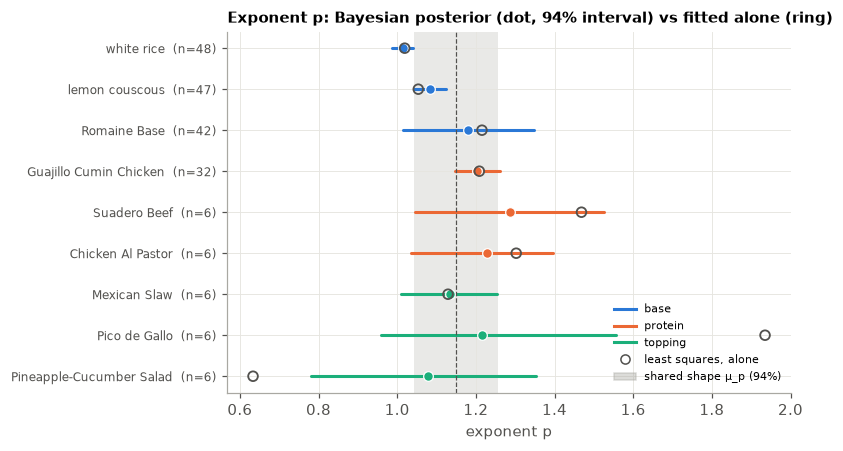

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
order = pool.reset_index(drop=True)
kind_color = {k: SERIES[i] for i, k in enumerate(["base", "protein", "topping"])}
for yi, r in order.iterrows():
    d = post["p"].sel(ingredient=r.ingredient).values
    lo, hi = hdi(d)
    c = kind_color[r.kind]
    ax.plot([lo, hi], [yi, yi], color=c, lw=2, solid_capstyle="round")
    ax.scatter(d.mean(), yi, s=40, color=c, edgecolor="white", linewidth=0.8, zorder=3)
    ax.scatter(r["p (LS)"], yi, s=40, facecolor="none", edgecolor=INK2, linewidth=1.2, zorder=4)
mp = post["mu_p"].values
ax.axvspan(*hdi(mp), color=MUTED, alpha=0.25, lw=0)
ax.axvline(mp.mean(), color=INK2, lw=0.8, ls="--")
ax.set_yticks(range(len(order)), [f"{r.ingredient}  (n={r.n})" for r in order.itertuples()], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("exponent p")
handles = [plt.Line2D([], [], color=kind_color[k], lw=2, label=k) for k in kind_color]
handles += [plt.Line2D([], [], marker="o", ls="", mfc="none", mec=INK2, label="least squares, alone"),
            plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=0.4, label="shared shape μ_p (94%)")]
ax.legend(handles=handles, fontsize=7, loc="lower right")
ax.set_title("Exponent p: Bayesian posterior (dot, 94% interval) vs fitted alone (ring)", loc="left")
fig.tight_layout()

### Batches

$\tau_\text{batch}$ is how much a new batch's volume typically differs from the ingredient's typical batch.
It is learned from every ingredient that has more than one session, and it applies to all of them, including
ingredients only ever measured once.

In [24]:
tb = post["tau_batch"].values
lo, hi = hdi(tb)
print(f"typical batch-to-batch shift: ±{100 * (np.exp(tb.mean()) - 1):.0f}% "
      f"(94% interval ±{100 * (np.exp(lo) - 1):.0f}% to ±{100 * (np.exp(hi) - 1):.0f}%)")
print("Only 3 ingredients have 2 sessions, so this spread is still loosely known.\n")
bt = pd.DataFrame({"batch": list(batches)})
bt[["ingredient", "session"]] = bt.batch.str.split(" | ", expand=True, regex=False)
bt["shift %"] = [100 * (np.exp(post["b"].sel(batch=k).values).mean() - 1) for k in bt.batch]
bt["94%"] = ["{:+.0f}% to {:+.0f}%".format(*(100 * (np.exp(np.array(hdi(post["b"].sel(batch=k).values))) - 1)))
             for k in bt.batch]
bt = bt[bt.groupby("ingredient").session.transform("size") > 1]
bt[["ingredient", "session", "shift %", "94%"]].style.hide(axis="index").format({"shift %": "{:+.1f}"})

typical batch-to-batch shift: ±15% (94% interval ±5% to ±27%)
Only 3 ingredients have 2 sessions, so this spread is still loosely known.



ingredient,session,shift %,94%
lemon couscous,20261007,-11.8,-30% to +6%
white rice,20261007_3,-0.9,-19% to +19%
Romaine Base,20261007_4,-3.9,-23% to +18%
Romaine Base,20261009_1,+12.2,-10% to +39%
lemon couscous,20261009_2,+9.9,-13% to +32%
white rice,20261019_1,+1.2,-17% to +23%


### Predicting a bowl before lidding

The simulator needs: given what's dispensed, how much volume will the bowl take up? The posterior answers with a
**distribution**, not a single number. Three cases for 250 g white rice + 180 g chicken:

1. **Known batch**: rice and Guajillo from the 10/19 session
2. **New batch**: same ingredients, from a batch we haven't measured; batch variation added
3. **Unmeasured protein**: 180 g of a protein with no data at all, predicted from the protein kind; new batch

Layers are added, which the unlidded mixed bowls in section 7 support to within about 1.5 %. Each scan's scatter is
added once per layer, a simple approximation. The least-squares point prediction (section 4's `power` fits) is
shown for comparison. `FILL_LINE_ML` is an illustrative threshold; set it to the bowl's real fill line.

case,median ml,80% range,P(> 700 ml)
known batch (10/19),692,667–716,0.33
new batch,692,589–825,0.46
"unmeasured protein, new batch",699,527–1014,0.50


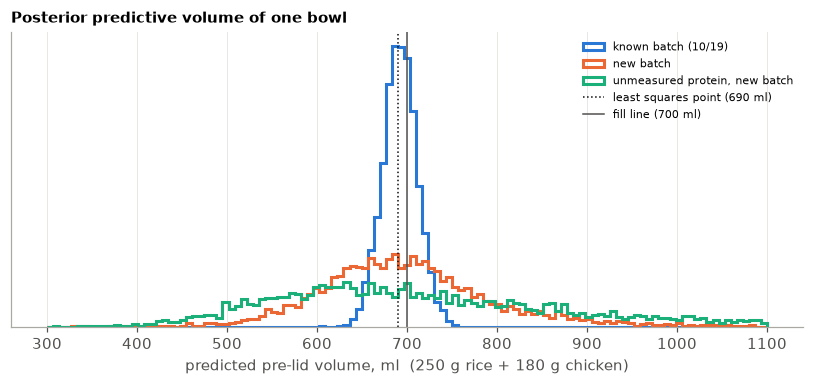

In [25]:
rng = np.random.default_rng(37)
FILL_LINE_ML = 700
S_draws = post.sizes["sample"]

def layer_draws(grams, name=None, kind=None, batch=None):
    # Posterior draws of one layer's ml. name=None means a new ingredient of `kind`.
    tau_b = post["tau_batch"].values
    if name is not None:
        logA_ = post["logA"].sel(ingredient=name).values
        p_ = post["p"].sel(ingredient=name).values
        sig = post["sigma"].sel(ingredient=name).values
    else:
        logA_ = rng.normal(post["mu_logA"].sel(kind=kind).values, post["tau_A"].values)
        p_ = rng.normal(post["mu_p"].values, post["tau_p"].values)
        sig = post["sigma"].values.mean(axis=0)            # scatter: average over measured foods
    if batch == "new" or name is None:
        b_ = rng.normal(0, tau_b)
    else:
        b_ = post["b"].sel(batch=f"{name} | {batch}").values
    mean = np.exp(logA_ + b_ + p_ * np.log(grams / 100))
    return mean + rng.normal(0, sig)

cases = {
    "known batch (10/19)": layer_draws(250, "white rice", batch="20261019_1")
                           + layer_draws(180, "Guajillo Cumin Chicken", batch="20261019_1"),
    "new batch": layer_draws(250, "white rice", batch="new") + layer_draws(180, "Guajillo Cumin Chicken", batch="new"),
    "unmeasured protein, new batch": layer_draws(250, "white rice", batch="new") + layer_draws(180, kind="protein"),
}
ls_point = sum(res.query("ingredient == @n and model == 'power'").pipe(
    lambda r: r.beta.iloc[0][0] * gr ** r.q.iloc[0]) for n, gr in [("white rice", 250), ("Guajillo Cumin Chicken", 180)])

summary_rows = []
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(300, 1100, 120)
for i, (label, d) in enumerate(cases.items()):
    ax.hist(d, bins=bins, density=True, histtype="step", lw=2, color=SERIES[i], label=label)
    q10, q50, q90 = np.percentile(d, [10, 50, 90])
    summary_rows.append({"case": label, "median ml": q50, "80% range": f"{q10:.0f}–{q90:.0f}",
                         f"P(> {FILL_LINE_ML} ml)": (d > FILL_LINE_ML).mean()})
ax.axvline(ls_point, color=INK, lw=1, ls=":", label=f"least squares point ({ls_point:.0f} ml)")
ax.axvline(FILL_LINE_ML, color=INK2, lw=1, label=f"fill line ({FILL_LINE_ML} ml)")
ax.set_yticks([])
ax.set_xlabel("predicted pre-lid volume, ml  (250 g rice + 180 g chicken)")
ax.legend(fontsize=7, loc="upper right")
ax.set_title("Posterior predictive volume of one bowl", loc="left")
fig.tight_layout()
pd.DataFrame(summary_rows).style.hide(axis="index").format({"median ml": "{:.0f}", f"P(> {FILL_LINE_ML} ml)": "{:.2f}"})

### What this adds over least squares, and what's next

*Numbers as of 2026-10-20; sampling is seeded, so a rerun on the same data reproduces them.*

- **Well-measured ingredients hardly change.** White rice p goes 1.019 → 1.014 and Guajillo 1.209 → 1.204. With 30–50
  points, the data dominate and the hierarchy agrees with least squares.
- **Sparse ingredients are pulled toward the shared shape.** Pico de Gallo goes from p = 1.94 alone to about 1.2, and
  Pineapple-Cucumber from 0.63 to about 1.08. Six points over a narrow range (Pico: 29–53 g) can't pin an exponent, and
  fitted alone, those curves give wild values once extrapolated. Pico's A₁₀₀ drops from 113 to 68 ml because 100 g is
  far outside its data. The wide intervals are the honest version of the app's `kBorrowedExtraRelSd`.
- **A new batch typically shifts volume by about ±15 %**, but that is loosely known (5–27 %), because only rice, couscous
  and Romaine have two sessions. The 10/07 couscous session sits about 12 % below typical and 10/09 about 10 % above,
  the shift section 4 found.
- **For filling bowls, batch variation is the biggest uncertainty.** For 250 g rice + 180 g Guajillo:
  - from a measured batch, the 80 % range is about ±25 ml;
  - from a new batch, it widens to about ±120 ml;
  - with an unmeasured protein, about ±240 ml.

  Least squares gives a single 690 ml with nothing to show batch risk. **More batches will narrow predictions more than
  more points per batch.** About five portions from each of several batches beats 40 portions from one.
- **Not in this model yet:** mixed bowls in the same fit (settling, toppings that sit on top), the camera zero and the
  test beans as calibration, error in the robot's grams, and greens split from grains. "Base" currently mixes rice and
  Romaine, whose A₁₀₀ differ about 2.4×, which inflates τ_A.
- **Getting it into the app:** export each ingredient's posterior mean as K = A₁₀₀ / 100ᵖ, plus p, through the existing
  Catalog export. For ranges, add τ_batch and the per-ingredient scatter. An unmeasured ingredient gets its kind's
  typical curve with the kind-level spread. The C++ side still evaluates K·gᵖ.

## 11. What a probability-based fill target looks like

**Volume Fill today** decides a bowl "fits" when its **single predicted volume** is within `fit_share` × food room
(default 100 %; lower it, say to 90 %, for headroom). The headroom is the same for every bowl, whether the
ingredients are measured well or guessed.

**A probability-based target** decides a bowl fits when **P(volume > food room) ≤ risk**, e.g. 10 %. The headroom
then comes out per bowl: small when the ingredients are well measured and from a known batch, large for sparse
ingredients or a new batch.

The example: the base (white rice) is adjusted, with 180 g Guajillo and 50 g Pico de Gallo on top. The food room is the
32 oz (946 ml) fill line, with no sauce cups. The question each rule answers: **how much rice?** Every rule is then
scored against section 10's posterior, i.e. how often each choice really overfills.

**Dispense error is included.** The robot asks for a target weight and delivers target × (1 + bias + noise), with
relative SD and bias by kind from the simulator's `DispenseVariation` (production data: 274k BowlStation dispenses,
2026-07-14 to 2026-10-12): base 10 % SD and +2.5 % bias, protein 12 % and +3.2 %, topping 19 % and +5.0 %.
A rule picks a **target**; whether the bowl overfills depends on what was actually dispensed.

In [26]:
FOOD_ROOM_ML = 946.0     # 32 oz functional fill, no sauce cups
RISK = 0.10              # allowed chance of overfilling the food room
rice_grid = np.arange(100.0, 500.0 + 1, 2.5)
RECIPE = [("Guajillo Cumin Chicken", 180.0), ("Pico de Gallo", 50.0)]   # fixed layers; rice is the base being stepped
KNOWN_BATCH = {"white rice": "20261019_1", "Guajillo Cumin Chicken": "20261019_1", "Pico de Gallo": "20261007_4"}

# How far the robot misses its target, by kind: (relative SD, average bias). Same as DispenseVariation in simulator.hh.
DISPENSE = {"base": (0.10, 0.025), "protein": (0.12, 0.032), "topping": (0.19, 0.050)}

rng11 = np.random.default_rng(11)
S11 = post.sizes["sample"]

def layer_matrix(target_g, name=None, kind=None, batch="new", dispense=True):
    # Posterior draws (rows) × target gram amounts (columns) of one layer's ml. The same random numbers are reused
    # across the gram columns, so P(overfill) is smooth in grams.
    target_g = np.atleast_1d(target_g)
    kind = kind or KIND[name]
    if name is not None:
        logA_ = post["logA"].sel(ingredient=name).values
        p_ = post["p"].sel(ingredient=name).values
        sig = post["sigma"].sel(ingredient=name).values
    else:                                            # an ingredient never measured: its kind's typical curve
        logA_ = rng11.normal(post["mu_logA"].sel(kind=kind).values, post["tau_A"].values)
        p_ = rng11.normal(post["mu_p"].values, post["tau_p"].values)
        sig = post["sigma"].values.mean(axis=0)
    if batch == "new":
        b_ = rng11.normal(0, post["tau_batch"].values)
    else:
        b_ = post["b"].sel(batch=f"{name} | {batch}").values
    if dispense:                                     # what the robot actually puts in the bowl
        sd, bias = DISPENSE[kind]
        grams = target_g[None, :] * np.clip(1 + bias + sd * rng11.standard_normal(S11), 0.05, None)[:, None]
    else:
        grams = np.broadcast_to(target_g[None, :], (S11, len(target_g)))
    mean = np.exp(logA_[:, None] + b_[:, None] + p_[:, None] * np.log(grams / 100))
    return mean + (sig * rng11.standard_normal(S11))[:, None]

def bowl_matrix(batch_mode, protein=None, dispense=True):
    # Total ml for each rice target in rice_grid. batch_mode: "known" or "new".
    pick = lambda n: KNOWN_BATCH[n] if batch_mode == "known" else "new"
    total = layer_matrix(rice_grid, "white rice", batch=pick("white rice"), dispense=dispense)
    for name, g in RECIPE:
        if name == "Guajillo Cumin Chicken" and protein == "unmeasured":
            total = total + layer_matrix(g, kind="protein", dispense=dispense)
        else:
            total = total + layer_matrix(g, name, batch=pick(name), dispense=dispense)
    return total

draws = {"new batch": bowl_matrix("new"),
         "new batch, curves only (no dispense error)": bowl_matrix("new", dispense=False),
         "unmeasured protein, new batch": bowl_matrix("new", protein="unmeasured"),
         "known batch": bowl_matrix("known")}
p_over = {k: (d > FOOD_ROOM_ML).mean(axis=0) for k, d in draws.items()}

# Today's rule: least-squares point prediction at the target grams ≤ fit_share × food room
def ls_point(name, g):
    gg, yy, _, _ = ingredient_data(name)
    q, beta, _, _ = fit("power", gg, yy, np.zeros(len(gg), int), 1)
    return beta[0] * np.asarray(g) ** q
point = ls_point("white rice", rice_grid) + sum(ls_point(n, g) for n, g in RECIPE)

def max_rice(ok):
    return rice_grid[ok].max() if ok.any() else np.nan

rules = {
    "today, fit_share 100%": max_rice(point <= FOOD_ROOM_ML),
    "today, fit_share 90%": max_rice(point <= 0.9 * FOOD_ROOM_ML),
    f"P(over) ≤ {RISK:.0%}, new batch": max_rice(p_over["new batch"] <= RISK),
    f"P(over) ≤ {RISK:.0%}, new batch, curves only": max_rice(p_over["new batch, curves only (no dispense error)"] <= RISK),
    f"P(over) ≤ {RISK:.0%}, unmeasured protein": max_rice(p_over["unmeasured protein, new batch"] <= RISK),
    f"P(over) ≤ {RISK:.0%}, known batch (calibration station)": max_rice(p_over["known batch"] <= RISK),
}
rows = []
for rule, rice in rules.items():
    i = int(np.argmin(np.abs(rice_grid - rice)))
    rows.append({"rule": rule, "rice target g": rice, "point prediction ml": point[i],
                 "median ml (new batch)": np.median(draws["new batch"][:, i]),
                 "P(over), new batch": p_over["new batch"][i],
                 "P(over), unmeasured protein": p_over["unmeasured protein, new batch"][i],
                 "P(over), known batch": p_over["known batch"][i]})
pd.DataFrame(rows).style.hide(axis="index").format(
    {"rice target g": "{:.1f}", "point prediction ml": "{:.0f}", "median ml (new batch)": "{:.0f}",
     "P(over), new batch": "{:.0%}", "P(over), unmeasured protein": "{:.0%}", "P(over), known batch": "{:.0%}"})

rule,rice target g,point prediction ml,median ml (new batch),"P(over), new batch","P(over), unmeasured protein","P(over), known batch"
"today, fit_share 100%",367.5,944,973,57%,56%,63%
"today, fit_share 90%",317.5,848,875,29%,38%,17%
"P(over) ≤ 10%, new batch",270.0,758,783,10%,24%,1%
"P(over) ≤ 10%, new batch, curves only",292.5,801,826,18%,30%,5%
"P(over) ≤ 10%, unmeasured protein",185.0,596,618,1%,10%,0%
"P(over) ≤ 10%, known batch (calibration station)",305.0,825,851,24%,34%,9%


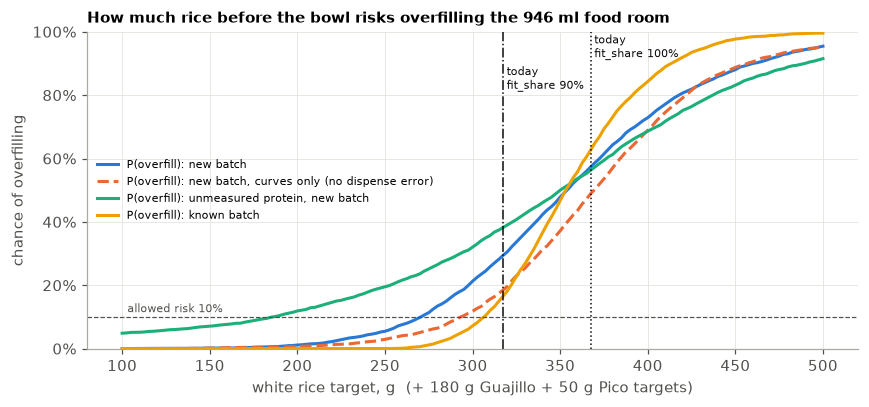

In [27]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (label, pv) in enumerate(p_over.items()):
    ax.plot(rice_grid, pv, color=SERIES[i], lw=2, ls="--" if "curves only" in label else "-", label=f"P(overfill): {label}")
ax.axhline(RISK, color=INK2, lw=0.8, ls="--")
ax.text(rice_grid[0] + 3, RISK + 0.015, f"allowed risk {RISK:.0%}", fontsize=7, color=INK2)
for rule, rice in rules.items():
    if rule.startswith("today"):
        ax.axvline(rice, color=INK, lw=1, ls=":" if "100" in rule else "-.")
        ax.text(rice + 2, 0.92 if "100" in rule else 0.82, rule.replace("today, ", "today\n"), fontsize=7, color=INK)
ax.set_xlabel("white rice target, g  (+ 180 g Guajillo + 50 g Pico targets)")
ax.set_ylabel("chance of overfilling")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(fontsize=7, loc="center left")
ax.set_title("How much rice before the bowl risks overfilling the 946 ml food room", loc="left")
fig.tight_layout()

### What the robot would need

The robot doesn't need the posterior or any sampling. A normal approximation is enough, and it has the same form as
the simulator's existing `fill_uncertainty` (`simulator.cc`), which already adds dispense error this way:

$$\text{fits} \iff \sum_i v_i + z \sqrt{\sum_i (r_i v_i)^2} \;\le\; \text{food room}, \qquad v_i = K_i\,\big(g_i(1 + \beta_\text{kind})\big)^{p_i}$$

$$r_i^2 = \underbrace{r_{\text{curve},i}^2}_{\text{batch + curve + bowl scatter}} + \underbrace{(p_i\, d_\text{kind})^2}_{\text{dispense error}}$$

- $g_i$ = the **target** grams; $\beta_\text{kind}$ = the robot's average heavy bias (+2.5 % base, +3.2 % protein, +5 % topping)
- $d_\text{kind}$ = dispense relative SD (10 %, 12 %, 19 %). A share *d* off in grams moves volume by about *p*·*d* along a power law.
- $r_{\text{curve},i}$ = the ingredient's relative SD for a new batch, from the posterior: **one number per ingredient**, exported next to K and p
- $z$ = SDs of headroom, from the allowed risk: 10 % → 1.28, 5 % → 1.64. It replaces `fit_share`.

Layers are treated as independent (different batches, separate dispenses), so their variances add. The cell below
computes $r$ with and without dispense error, and checks that the approximation picks nearly the same rice target
as the full posterior.

In [28]:
from statistics import NormalDist

def rel_sd(name, grams):
    d = layer_matrix(grams, name, batch="new", dispense=False)[:, 0]   # batch + curve + bowl scatter only
    return d.std() / d.mean()

def K_p(name):
    A = np.exp(post["logA"].sel(ingredient=name).values.mean())
    p_ = post["p"].sel(ingredient=name).values.mean()
    return A / 100 ** p_, p_

rows = []
for n, g in [("white rice", 250.0)] + RECIPE:
    K, p_ = K_p(n)
    sd, bias = DISPENSE[KIND[n]]
    r_curve = rel_sd(n, g)
    rows.append({"ingredient": n, "kind": KIND[n], "K": K, "p": p_, "r_curve": r_curve,
                 "dispense p·d": p_ * sd, "r (total)": math.hypot(r_curve, p_ * sd), "bias β": bias})
export = pd.DataFrame(rows)
display(export.style.hide(axis="index").format({"K": "{:.4f}", "p": "{:.3f}", "r_curve": "{:.1%}",
                                                "dispense p·d": "{:.1%}", "r (total)": "{:.1%}", "bias β": "{:+.1%}"}))

z = NormalDist().inv_cdf(1 - RISK)
E = export.set_index("ingredient")
def robot_rice(r_col, with_bias):
    vol = lambda n, g: E.loc[n, "K"] * (np.asarray(g) * (1 + (E.loc[n, "bias β"] if with_bias else 0))) ** E.loc[n, "p"]
    names = ["white rice"] + [n for n, _ in RECIPE]
    layers = [vol("white rice", rice_grid)] + [vol(n, g) * np.ones_like(rice_grid) for n, g in RECIPE]
    mean_ml = sum(layers)
    sd_ml = np.sqrt(sum((E.loc[n, r_col] * v) ** 2 for n, v in zip(names, layers)))
    return max_rice(mean_ml + z * sd_ml <= FOOD_ROOM_ML)

print(f"z = {z:.2f} for {RISK:.0%} risk")
print(f"with dispense error: robot formula picks {robot_rice('r (total)', True):.1f} g rice; "
      f"full posterior picks {rules[f'P(over) ≤ {RISK:.0%}, new batch']:.1f} g")
print(f"curves only:         robot formula picks {robot_rice('r_curve', False):.1f} g rice; "
      f"full posterior picks {rules[f'P(over) ≤ {RISK:.0%}, new batch, curves only']:.1f} g")

ingredient,kind,K,p,r_curve,dispense p·d,r (total),bias β
white rice,base,1.7237,1.014,18.9%,10.1%,21.4%,+2.5%
Guajillo Cumin Chicken,protein,0.4282,1.204,22.0%,14.4%,26.3%,+3.2%
Pico de Gallo,topping,0.2464,1.215,37.6%,23.1%,44.1%,+5.0%


z = 1.28 for 10% risk
with dispense error: robot formula picks 270.0 g rice; full posterior picks 270.0 g
curves only:         robot formula picks 292.5 g rice; full posterior picks 292.5 g


### Reading it

*Numbers as of 2026-10-20, from section 10's posterior; the fill line and the risk level are settings.*

**In production every batch is a new batch.** Ingredients are used up, so the robot never fills from a batch the curves
were measured on. The **new-batch** rows are the ones that apply. The known-batch rows only show what measuring the
current batch would be worth, for example by updating its batch shift from the robot's own scans of the first few
bowls (if production bowls are scanned). That narrows the headroom as a batch goes on and resets when it changes.

- **A fixed fit share ignores uncertainty, and it also ignores the robot running heavy.** The point prediction is made
  at the *target* grams. The robot delivers about 3 % more on average, so a 100 % fit share (367.5 g rice) overfills
  57 % of new-batch bowls, and 90 % (317.5 g) still overfills 29 %.
- **The probability rule at 10 % risk:**
  - new batch: 270 g rice target, about 83 % of the food room at the median;
  - unmeasured protein: 185 g;
  - a batch measured at a future calibration station: 305 g.
- **Dispense error matters.** Leaving it out (curves only) would pick 292.5 g, which really overfills 18 % of the time,
  not 10 %. With it, r per ingredient is: rice 21 % (19 % curve and batch, 10 % dispense), Guajillo 26 %, Pico 44 %.
- **The robot formula matches the full posterior** (270.0 g with dispense error, 292.5 g without). The robot needs
  K, p, r and the bias per ingredient (bias is per kind, and already in the simulator), plus one z in place of `fit_share`.
- **Today's r values are large**, mostly from the batch spread and from uncertainty about each ingredient's typical
  batch. The headroom shrinks as more batches are measured. Underfilling has a cost too: the same machinery can also
  enforce, for example, "P(under 75 % of the food room) ≤ 10 %".
- **Not modeled here:** settling (about 1.5 % unlidded), sauce cups, and toppings that sit on top.